# 🍊 Orange Vision v4: YOLOv8n, YOLO11n, YOLOv8m y YOLO11m en tres etapas

**Objetivo:** comparar cuatro detectores de naranjas en fotos de campo y medir, para cada uno, cuánto aporta cada etapa del aprendizaje:

| Etapa | Qué es | Entrenamiento con nuestras fotos |
|---|---|---|
| **Pura (COCO)** | El modelo tal como viene, preentrenado en COCO, usando su clase *orange* | Ninguno |
| **Transfer learning** | Backbone congelado; solo se entrenan neck y head (Fase 1) | 10 épocas máx. |
| **Fine-tuning** | Después de la Fase 1, se entrena toda la red con un *learning rate* 10 veces menor (Fase 2) | 10 + 40 épocas máx. |

Todos los modelos usan las mismas imágenes, el mismo presupuesto de entrenamiento y la misma evaluación.

| Sección | Qué se hace | Teoría incluida |
|---|---|---|
| 1. Configuración | Librerías, ajustes, carpetas y estilo de las gráficas | — |
| 2. Datos | Descarga, división train / val / test, reutilizar entrenamientos de v3 | Conjuntos de datos, fuga de datos |
| 3. Teoría y línea base | YOLO de COCO sin entrenar | Redes neuronales, CNN, detección, YOLOv8 vs YOLO11, atención |
| 4. Entrenamiento | Fase 1 (transfer learning) y Fase 2 (fine-tuning) | Funciones de pérdida, *learning rate*, AdamW, sobreajuste, aumento de datos, pura vs transfer learning vs fine-tuning |
| 5. Evaluación | Las 3 etapas en test, matriz de confusión, por entorno, velocidad | IoU, TP / FP / FN, precisión, recall, F1, AP, mAP, latencia |
| 6. Gráficas | 15 gráficas, cada una con su explicación | Cómo leer cada gráfica |
| 7. Conclusiones | Resumen automático y preguntas guía | — |
| 8. Guardar | Modelos y elección del modelo final | Por qué se elige con validación |
| 9. Usar el modelo | Subir una imagen o usar la webcam, **sin volver a entrenar** | — |
| 10. Glosario | Resumen de conceptos y métricas | — |

| Carpeta | Contenido |
|---|---|
| `resultados/v4_N1000/runs/` | Cada entrenamiento (`f1_…` = Fase 1 = transfer learning, `f2_…` = Fase 2 = fine-tuning) con `weights/best.pt` y `results.csv` |
| `resultados/v4_N1000/` | Tablas `.csv` y gráficas `.png` (`G1_…` a `G15_…`) |
| `modelos/v4/` | Los mejores modelos fine-tuned (`orange_yolov8n.pt`, …) y `modelos.json`. Los modelos de v3 en `modelos/` no se tocan |

Las imágenes del dataset se descargan en el disco local de Colab (`/content`), que es mucho más rápido que Drive.

**Dataset:** Lucas et al., *Oranges in the field*, Mendeley Data, https://doi.org/10.17632/93f32zgkxz.1 (licencia CC BY-NC 3.0).

---
## 1. Configuración

In [ ]:
# 1.1 Instalar (si hace falta) e importar librerías
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.175'], check=True)

import gc
import json
import re
import shutil
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Patch
from ultralytics import YOLO, settings
from ultralytics.utils.torch_utils import get_flops, get_num_params

settings.update({'tensorboard': False})  # Las curvas se dibujan en la sección 6 a partir de results.csv
print('torch', torch.__version__, '| ultralytics', ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
torch 2.14.1+cu130 | ultralytics 8.4.175


In [ ]:
# 1.2 Configuración del experimento
PERFIL = 'completo'         # 'rapido': 1 semilla (≈ 1 h en T4; ≈ 35 min reutilizando v3) | 'completo': 3 semillas (≈ 3 h)
N_IMAGENES = 1500         # Cuántas imágenes usar (máximo 5025). None = todas
ENTORNOS_COMPLETOS = ['IN']  # De estos entornos se incluyen todas las imágenes (interior = primer despliegue)

SEMILLAS = {'rapido': [0], 'completo': [0, 1, 2]}[PERFIL]

# pesos    = modelo preentrenado en COCO: punto de partida del entrenamiento y modelo de la etapa "Pura"
# congelar = capas del backbone que no se entrenan en la Fase 1 (YOLOv8: capas 0-9 → 10; YOLO11: capas 0-10 → 11)
# lr0      = learning rate de la Fase 1. YOLO11: elegido con validación en un notebook anterior.
#            YOLOv8: el mismo valor que el YOLO11 del mismo tamaño (no se repite el barrido; ver 4.2)
# El orden (n, n, m, m) pone juntos los modelos del mismo tamaño en tablas y gráficas.
MODELOS = {
    'YOLOv8n': {'pesos': 'yolov8n.pt', 'congelar': 10, 'lr0': 1e-3},
    'YOLO11n': {'pesos': 'yolo11n.pt', 'congelar': 11, 'lr0': 1e-3},
    'YOLOv8m': {'pesos': 'yolov8m.pt', 'congelar': 10, 'lr0': 3e-4},
    'YOLO11m': {'pesos': 'yolo11m.pt', 'congelar': 11, 'lr0': 3e-4},
}

EPOCAS_FASE1 = 10   # Fase 1 (transfer learning): backbone congelado
EPOCAS_FASE2 = 40   # Fase 2 (fine-tuning): toda la red, learning rate 10 veces menor
PACIENCIA = 10      # Early stopping: se detiene si mAP50-95 de validación no mejora en estas épocas
IMGSZ = 640         # Las imágenes del dataset ya son de 640x640
BATCH = 16          # Si aparece "CUDA out of memory", bajar a 8
OPTIMIZADOR = 'AdamW'

FRACCION_VAL, FRACCION_TEST = 0.10, 0.20   # El resto (70 %) es para entrenar
SEMILLA_DATOS = 42                         # Hace que la división sea siempre la misma

# Aumento de datos, igual para los cuatro modelos (ver sección 4.5)
AUMENTACION = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, translate=0.1, scale=0.5, fliplr=0.5, mosaic=1.0)

# YOLO11n y YOLO11m ya se entrenaron en v3 con estos mismos ajustes: se copian si todo coincide (ver 2.3)
REUTILIZAR_V3 = True
EXPERIMENTO_V3 = 'N1000'

In [ ]:
# 1.3 Carpetas: resultados y modelos en la carpeta del proyecto (Drive), imágenes en disco local
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA_PROYECTO = Path('/content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto')
    CARPETA_DATOS = Path('/content/datos_naranjas')
else:
    CARPETA_PROYECTO = Path.cwd()   # La carpeta donde está este notebook
    CARPETA_DATOS = Path.home() / 'datos_naranjas'

if not CARPETA_PROYECTO.exists():
    raise FileNotFoundError(f'No existe {CARPETA_PROYECTO}. Corrige la ruta de CARPETA_PROYECTO.')

NOMBRE_EXPERIMENTO = f"v4_N{N_IMAGENES or 'todas'}"
CARPETA_RESULTADOS = CARPETA_PROYECTO / 'resultados' / NOMBRE_EXPERIMENTO
RUNS = CARPETA_RESULTADOS / 'runs'
CARPETA_MODELOS = CARPETA_PROYECTO / 'modelos' / 'v4'   # Los modelos de v3 siguen en modelos/
CARPETA_DATASET = CARPETA_DATOS / NOMBRE_EXPERIMENTO
for carpeta in (RUNS, CARPETA_MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Protección: si cambias ajustes de entrenamiento, no se mezclan con entrenamientos anteriores.
# (PERFIL no cuenta: el perfil 'completo' reutiliza la semilla 0 que ya entrenó el perfil 'rapido'.)
CONFIG = dict(N_IMAGENES=N_IMAGENES, ENTORNOS_COMPLETOS=ENTORNOS_COMPLETOS, MODELOS=MODELOS, EPOCAS_FASE1=EPOCAS_FASE1,
              EPOCAS_FASE2=EPOCAS_FASE2, PACIENCIA=PACIENCIA, IMGSZ=IMGSZ, BATCH=BATCH, OPTIMIZADOR=OPTIMIZADOR,
              FRACCION_VAL=FRACCION_VAL, FRACCION_TEST=FRACCION_TEST, SEMILLA_DATOS=SEMILLA_DATOS, AUMENTACION=AUMENTACION)
ruta_config = CARPETA_RESULTADOS / 'configuracion.json'
if ruta_config.exists() and json.loads(ruta_config.read_text(encoding='utf-8')) != json.loads(json.dumps(CONFIG)):
    raise RuntimeError(f'{ruta_config} tiene otros ajustes. Cambia NOMBRE_EXPERIMENTO (p. ej. "v4_N1000_b") '
                       'o borra esa carpeta para empezar de cero.')
ruta_config.write_text(json.dumps(CONFIG, indent=2), encoding='utf-8')

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'sin GPU'
print('Perfil:', PERFIL, '| semillas:', SEMILLAS, '| GPU:', GPU)
print('Resultados en:', CARPETA_RESULTADOS)
print('Modelos en:   ', CARPETA_MODELOS)

Mounted at /content/drive
Perfil: completo | semillas: [0, 1, 2] | GPU: Tesla T4
Resultados en: /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/resultados/v4_N1500
Modelos en:    /content/drive/MyDrive/Facultad/9no semestre/IA/Proyecto/modelos/v4


In [ ]:
# 1.4 Funciones de uso general y estilo de las gráficas
ORDEN = list(MODELOS)
ETAPAS = ['Pura (COCO)', 'Transfer learning', 'Fine-tuning']
ETAPA_CORTA = {'Pura (COCO)': 'Pura', 'Transfer learning': 'TL', 'Fine-tuning': 'FT'}
METRICAS = ['Precisión', 'Recall', 'F1', 'mAP50', 'mAP50-95']

# Un color por modelo: el tono indica la generación (azul = YOLOv8, naranja = YOLO11) y la intensidad el tamaño (claro = n, oscuro = m)
COLORES = {'YOLOv8n': '#74B9FF', 'YOLOv8m': '#1F6FB2', 'YOLO11n': '#FF9F43', 'YOLO11m': '#E8503A'}
LINEA = {'YOLOv8n': '--', 'YOLOv8m': '--', 'YOLO11n': '-', 'YOLO11m': '-'}   # En curvas: discontinua = YOLOv8
CAPA = {'YOLOv8n': 3, 'YOLOv8m': 3, 'YOLO11n': 2, 'YOLO11m': 2}             # YOLOv8 (discontinua) encima, para que no la tape YOLO11
# Cuando aparecen las tres etapas, la intensidad del color indica la etapa: pálido = Pura, medio = TL, lleno = FT
ALFA_ETAPA = {'Pura (COCO)': 0.30, 'Transfer learning': 0.60, 'Fine-tuning': 1.0}

# Estética de las gráficas de v1
COLOR_FONDO, COLOR_TEXTO, COLOR_GRID = '#FFF3EB', '#2B1E19', '#F0D5C7'
plt.rcParams.update({
    'figure.facecolor': COLOR_FONDO, 'axes.facecolor': COLOR_FONDO, 'savefig.facecolor': COLOR_FONDO,
    'axes.edgecolor': COLOR_GRID, 'axes.labelcolor': COLOR_TEXTO, 'text.color': COLOR_TEXTO,
    'xtick.color': COLOR_TEXTO, 'ytick.color': COLOR_TEXTO, 'font.size': 9,
    'axes.titleweight': 'bold', 'axes.titlesize': 10.5, 'axes.labelweight': 'bold', 'figure.titleweight': 'bold',
    'axes.grid': True, 'grid.color': COLOR_GRID, 'grid.linestyle': '--', 'grid.alpha': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.facecolor': 'white', 'legend.edgecolor': 'none', 'legend.framealpha': 0.9, 'figure.dpi': 110})


def guardar(fig, nombre):
    """Guarda la figura en la carpeta de resultados y la muestra."""
    fig.savefig(CARPETA_RESULTADOS / nombre, dpi=200, bbox_inches='tight')
    plt.show()


def cargar_modelo(pesos):
    return YOLO(str(pesos))


def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def a_rgb(imagen_bgr):
    """OpenCV trabaja en BGR y matplotlib en RGB."""
    return cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

---
## 2. Datos: *Oranges in the field*

El dataset tiene **5025 fotos de 640×640** de naranjos, tomadas en 9 condiciones distintas. Las dos primeras letras de cada archivo indican el entorno:

| Código | Entorno | Código | Entorno | Código | Entorno |
|---|---|---|---|---|---|
| MS | Mañana, soleado | AC | Tarde, nublado | ES | Atardecer, soleado |
| MC | Mañana, nublado | AS | Tarde, soleado | EC | Atardecer, nublado |
| AR | Tarde, lluvia | NI | Noche | IN | Interior |

Cada imagen tiene un archivo `.txt` con una línea por naranja, en **formato YOLO**:
`clase  x_centro  y_centro  ancho  alto`, todo normalizado entre 0 y 1 (por ejemplo `0 0.52 0.31 0.08 0.09`).

### Train, validación y test
| Conjunto | % | Para qué sirve | Analogía |
|---|---|---|---|
| **Train** | 70 % | El modelo aprende de estas imágenes (ajusta sus pesos) | Estudiar con los ejercicios del libro |
| **Validación** | 10 % | Tomar decisiones: mejor época, *learning rate*, umbral, mejor modelo | Exámenes de práctica |
| **Test** | 20 % | Medir el resultado final **una sola vez**, al terminar | El examen final |

Si usáramos test para tomar decisiones, el modelo quedaría "afinado" para esas imágenes y el resultado sería optimista.

### Fuga de datos (*data leakage*)
Las fotos con el mismo ID (por ejemplo `MS12_…_1.jpg`, `MS12_…_2.jpg`) son casi iguales: el mismo árbol fotografiado varias veces.
Si una cayera en train y otra en test, el modelo "ya habría visto" la imagen del examen. Por eso **todas las fotos de un mismo ID van al mismo conjunto**.

### Subconjunto
Para entrenar más rápido se usan `N_IMAGENES` (1000 por defecto): todas las de interior (`IN`, el primer lugar donde se usará el sistema)
y el resto repartido de forma proporcional entre los demás entornos.

In [ ]:
# 2.1 Funciones para descargar y dividir el dataset
API_DATASET = 'https://data.mendeley.com/public-api/datasets/93f32zgkxz'
CABECERA = {'User-Agent': 'Mozilla/5.0'}
PATRON_ARCHIVO = re.compile(r'^(([A-Z]{2})\d+)_(\d{4}-\d{2}-\d{2})_(\d+)\.jpg$')   # ID, entorno, fecha, número
ENTORNOS = {'MS': 'Mañana, soleado', 'AC': 'Tarde, nublado', 'AS': 'Tarde, soleado', 'ES': 'Atardecer, soleado',
            'MC': 'Mañana, nublado', 'NI': 'Noche', 'IN': 'Interior', 'EC': 'Atardecer, nublado', 'AR': 'Tarde, lluvia'}
FRACCIONES = {'train': 1 - FRACCION_VAL - FRACCION_TEST, 'val': FRACCION_VAL, 'test': FRACCION_TEST}


def listar_imagenes():
    """Una fila por imagen con su ID, entorno y las URLs de la imagen y de su etiqueta."""
    peticion = urllib.request.Request(API_DATASET, headers=CABECERA)
    with urllib.request.urlopen(peticion, timeout=60) as r:
        archivos = json.loads(r.read().decode('utf-8'))['files']
    etiquetas = {a['filename'][:-4]: a['content_details']['download_url'] for a in archivos if a['filename'].endswith('.txt')}
    filas = []
    for a in archivos:
        m = PATRON_ARCHIVO.match(a['filename'])
        if m and a['filename'][:-4] in etiquetas:
            filas.append({'archivo': a['filename'], 'id': m[1], 'entorno': m[2],
                          'url_img': a['content_details']['download_url'], 'url_lbl': etiquetas[a['filename'][:-4]]})
    return pd.DataFrame(filas).sort_values('archivo').reset_index(drop=True)


def dividir_por_id(df):
    """Asigna cada ID completo a train, val o test, entorno por entorno, para respetar las proporciones."""
    split_de_id = {}
    for entorno, grupo in df.groupby('entorno'):
        tamanos = grupo.groupby('id').size()
        ids = tamanos.sample(frac=1, random_state=SEMILLA_DATOS).sort_values(ascending=False, kind='stable')
        asignadas = dict.fromkeys(FRACCIONES, 0)
        for id_, n in ids.items():
            # El ID va al conjunto que está más lejos de su objetivo
            split = max(FRACCIONES, key=lambda s: FRACCIONES[s] * len(grupo) - asignadas[s])
            split_de_id[id_] = split
            asignadas[split] += n
    return df.assign(split=df['id'].map(split_de_id))


def elegir_subconjunto(df, n):
    """n imágenes: todas las de ENTORNOS_COMPLETOS y el resto proporcional por entorno, dentro de cada split."""
    if n is None or n >= len(df):
        return df
    partes = []
    for split, fraccion in FRACCIONES.items():
        del_split = df[df['split'] == split]
        fijas = del_split[del_split['entorno'].isin(ENTORNOS_COMPLETOS)]
        resto = del_split[~del_split['entorno'].isin(ENTORNOS_COMPLETOS)]
        faltan = max(round(n * fraccion) - len(fijas), 0)
        muestra = resto.groupby('entorno').sample(frac=min(faltan / len(resto), 1), random_state=SEMILLA_DATOS)
        partes += [fijas, muestra]
    return pd.concat(partes).sort_values(['split', 'archivo']).reset_index(drop=True)


def descargar(url, destino):
    if destino.exists() and destino.stat().st_size > 0:
        return
    temporal = destino.with_name(destino.name + '.part')
    for intento in range(4):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=CABECERA), timeout=60) as r:
                temporal.write_bytes(r.read())
            temporal.replace(destino)
            return
        except Exception:
            if intento == 3:
                raise
            time.sleep(2 ** intento)


def preparar_dataset(seleccion):
    """Descarga imágenes y etiquetas en la estructura que espera Ultralytics y escribe data.yaml."""
    trabajos = []
    for fila in seleccion.itertuples():
        for tipo, url, nombre in (('images', fila.url_img, fila.archivo), ('labels', fila.url_lbl, fila.archivo[:-4] + '.txt')):
            destino = CARPETA_DATASET / tipo / fila.split / nombre
            destino.parent.mkdir(parents=True, exist_ok=True)
            trabajos.append((url, destino))
    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(lambda t: descargar(*t), trabajos))
    ruta_yaml = CARPETA_DATASET / 'data.yaml'
    ruta_yaml.write_text(f'path: {CARPETA_DATASET.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\n'
                         'names:\n  0: orange\n', encoding='utf-8')
    return str(ruta_yaml)


def ruta_imagen(archivo, split):
    return CARPETA_DATASET / 'images' / split / archivo


def leer_cajas(archivo, split, ancho=640, alto=640):
    """Cajas reales de una imagen en píxeles: una fila (x1, y1, x2, y2) por naranja."""
    ruta = CARPETA_DATASET / 'labels' / split / (archivo[:-4] + '.txt')
    texto = ruta.read_text().strip() if ruta.exists() else ''
    if not texto:
        return np.zeros((0, 4))
    e = np.array([linea.split() for linea in texto.splitlines()], dtype=float)
    xc, yc, w, h = e[:, 1] * ancho, e[:, 2] * alto, e[:, 3] * ancho, e[:, 4] * alto
    return np.c_[xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2]

In [ ]:
# 2.2 Descargar y dividir
seleccion = elegir_subconjunto(dividir_por_id(listar_imagenes()), N_IMAGENES)
assert seleccion.groupby('id')['split'].nunique().max() == 1, 'Fuga de datos: un ID quedó en dos conjuntos'

# Comprobar que la división es la misma que en ejecuciones anteriores de este experimento
ruta_division = CARPETA_RESULTADOS / 'division.csv'
division = seleccion[['archivo', 'id', 'entorno', 'split']]
if ruta_division.exists():
    if not pd.read_csv(ruta_division).equals(division.reset_index(drop=True)):
        raise RuntimeError(f'La división no coincide con {ruta_division}. Usa otro NOMBRE_EXPERIMENTO.')
else:
    division.to_csv(ruta_division, index=False)

print(f'Descargando {len(seleccion)} imágenes en {CARPETA_DATASET} ...')
DATA = preparar_dataset(seleccion)

seleccion['naranjas'] = [len(leer_cajas(f.archivo, f.split)) for f in seleccion.itertuples()]
RESUMEN_DATOS = seleccion.groupby('split').agg(imagenes=('archivo', 'size'), naranjas=('naranjas', 'sum'), ids=('id', 'nunique'))
display(RESUMEN_DATOS.loc[['train', 'val', 'test']])
display(pd.crosstab(seleccion['entorno'].map(lambda e: f'{e} ({ENTORNOS[e]})'), seleccion['split'], margins=True))

Descargando 1502 imágenes en /content/datos_naranjas/v4_N1500 ...


,imagenes,naranjas,ids
split,,,
train,1050,7612,331
val,152,1883,92
test,300,3154,143


split,test,train,val,All
entorno,,,,
"AC (Tarde, nublado)",60,222,33,315
"AR (Tarde, lluvia)",0,4,0,4
"AS (Tarde, soleado)",34,128,19,181
"EC (Atardecer, nublado)",2,7,1,10
"ES (Atardecer, soleado)",12,46,7,65
IN (Interior),27,30,0,57
"MC (Mañana, nublado)",7,26,4,37
"MS (Mañana, soleado)",153,568,84,805
NI (Noche),5,19,4,28


### 2.3 Reutilizar los entrenamientos de v3
YOLO11n y YOLO11m ya se entrenaron en v3 con **exactamente** los mismos ajustes: mismas imágenes, misma división, mismas épocas, mismo *learning rate* y mismo aumento de datos.
Volver a entrenarlos daría el mismo tipo de resultado y costaría ≈ 25 min de GPU.

Esta celda copia esos entrenamientos (`f1_…` y `f2_…`) a la carpeta de v4 **solo si** la división train / val / test y todos los ajustes coinciden.
Si algo es distinto no copia nada, y la sección 4 los entrena de nuevo. Pon `REUTILIZAR_V3 = False` en la celda 1.2 para entrenarlo todo desde cero.

In [ ]:
# 2.3 Copiar los entrenamientos de v3 que se puedan reutilizar
def reutilizar_v3():
    carpeta_v3 = CARPETA_PROYECTO / 'resultados' / EXPERIMENTO_V3
    ruta_cfg, ruta_div = carpeta_v3 / 'configuracion.json', carpeta_v3 / 'division.csv'
    if not (ruta_cfg.exists() and ruta_div.exists()):
        print(f'No se encontró {carpeta_v3}: se entrena todo desde cero.')
        return
    cfg_v3 = json.loads(ruta_cfg.read_text(encoding='utf-8'))
    cfg_v4 = json.loads(json.dumps(CONFIG))
    otros_ajustes_iguales = all(cfg_v3.get(k) == v for k, v in cfg_v4.items() if k != 'MODELOS')
    misma_division = pd.read_csv(ruta_div).equals(division.reset_index(drop=True))
    if not (otros_ajustes_iguales and misma_division):
        print('Los ajustes o la división de v3 son distintos: se entrena todo desde cero.')
        return
    copiados = 0
    for tipo, cfg in cfg_v4['MODELOS'].items():
        if cfg_v3['MODELOS'].get(tipo) != cfg:   # Modelo nuevo en v4 o con otros ajustes
            continue
        for semilla in SEMILLAS:
            origenes = {fase: carpeta_v3 / 'runs' / f'{fase}_{tipo}_s{semilla}' for fase in ('f1', 'f2')}
            if not all((o / 'terminado.txt').exists() for o in origenes.values()):
                continue
            for fase, origen in origenes.items():
                destino = RUNS / origen.name
                if not (destino / 'terminado.txt').exists():
                    shutil.rmtree(destino, ignore_errors=True)
                    shutil.copytree(origen, destino, ignore=shutil.ignore_patterns('desktop.ini'))
                    print(f'✔ Copiado de v3: {origen.name}')
                    copiados += 1
    print(f'{copiados} entrenamientos copiados de v3.')


if REUTILIZAR_V3:
    reutilizar_v3()

Los ajustes o la división de v3 son distintos: se entrena todo desde cero.


---
## 3. Teoría: de la neurona al detector de objetos

### 3.1 Redes neuronales
Una **neurona artificial** recibe números $x_1, \dots, x_n$, los multiplica por unos **pesos** $w_i$, suma un **sesgo** $b$ y aplica una **función de activación** $f$:

$$y = f\left(\sum_i w_i x_i + b\right)$$

La activación (por ejemplo ReLU: $f(z) = \max(0, z)$) introduce no linealidad; sin ella, muchas capas equivaldrían a una sola.
Una **red neuronal** apila muchas capas de neuronas. Los pesos empiezan con valores aleatorios y el **entrenamiento** consiste en ajustarlos para que la salida sea la correcta.
Cuando la red tiene muchas capas hablamos de ***deep learning*** (aprendizaje profundo).

### 3.2 Redes neuronales convolucionales (CNN)
Una imagen de 640×640 en color son $640 \times 640 \times 3 \approx 1.2$ millones de números. Si cada neurona de la primera capa se conectara a todos ellos,
una sola capa de 1000 neuronas necesitaría 1200 millones de pesos. Las CNN resuelven esto con la **convolución**:

- Un **filtro** (o *kernel*) es una pequeña matriz de pesos, por ejemplo de 3×3, que **se desliza** por toda la imagen.
  En cada posición multiplica sus pesos por los píxeles de debajo y los suma. El resultado es un **mapa de características** (*feature map*).
- El **mismo filtro se usa en toda la imagen** (pesos compartidos): un borde se detecta igual arriba que abajo y se necesitan muy pocos pesos.
- Cada capa aplica decenas o cientos de filtros. Con el *stride* (saltos de 2 píxeles) los mapas se hacen más pequeños y cada neurona "ve" una zona mayor.

Las capas forman una **jerarquía**: las primeras detectan bordes y colores, las intermedias texturas y formas (algo redondo y naranja),
y las profundas objetos completos (una naranja entre hojas). Nadie programa estos filtros: **se aprenden** durante el entrenamiento.

### 3.3 Estructura de un detector: backbone, neck y head
```
 imagen 640x640 ──► BACKBONE ──────────► NECK ─────────────────► HEAD ──────────────► cajas + clase + confianza
                    (extrae               (combina mapas de        (predice dónde están
                    características)       distintos tamaños:       los objetos)
                                           objetos grandes y pequeños)
```
- **Backbone**: la parte "que ve". Convierte la imagen en mapas de características. Es la parte más general y reutilizable.
- **Neck**: mezcla mapas de varias escalas, importante porque hay naranjas cercanas (grandes) y lejanas (pequeñas).
- **Head**: la parte específica de la tarea. Para cada zona predice una caja y una puntuación por clase.

### 3.4 Modelos preentrenados y COCO
Entrenar un backbone desde cero requiere millones de imágenes. Por eso se parte de modelos **preentrenados** en **COCO**,
un dataset de ~118 000 imágenes con 80 clases (personas, coches, perros… y también *orange*).
Sus filtros ya saben detectar bordes, texturas y formas: solo hay que adaptarlos a nuestras naranjas.
En la celda siguiente vemos qué tal lo hace YOLO11n de COCO **sin ningún entrenamiento extra**. Esta es la etapa **Pura**: la **línea base** que el *transfer learning* y el *fine-tuning* deberían superar. En la sección 5 se mide con números para los cuatro modelos.

COCO conoce 80 clases; "orange" es la clase 49.


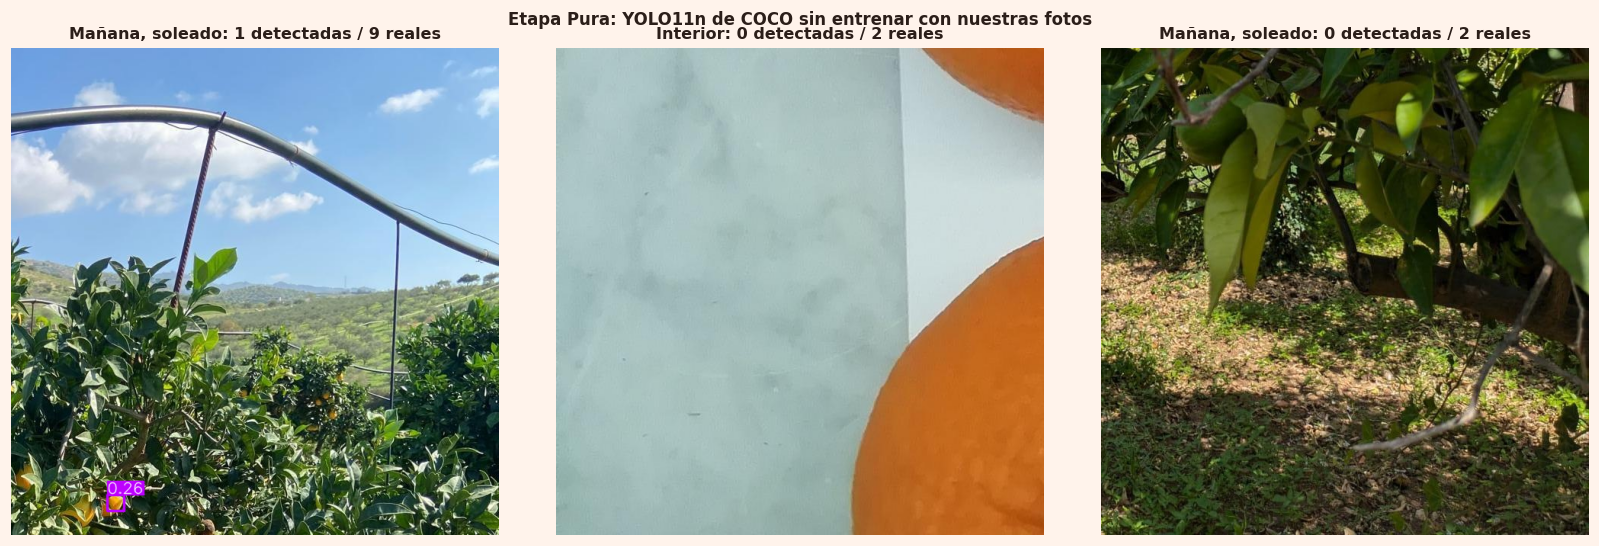

In [ ]:
# 3.5 Etapa Pura: YOLO11n preentrenado en COCO, sin entrenar con nuestras imágenes
modelo_coco = YOLO('yolo11n.pt')
ID_NARANJA_COCO = next(k for k, v in modelo_coco.names.items() if v == 'orange')
print(f'COCO conoce {len(modelo_coco.names)} clases; "orange" es la clase {ID_NARANJA_COCO}.')

test_tabla = seleccion[seleccion['split'] == 'test']
ejemplos = test_tabla.sample(3, random_state=1)['archivo']
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for ax, archivo in zip(ejes, ejemplos):
    r = modelo_coco.predict(str(ruta_imagen(archivo, 'test')), classes=[ID_NARANJA_COCO], conf=0.25, verbose=False)[0]
    ax.imshow(a_rgb(r.plot(labels=False)))
    ax.set_title(f'{ENTORNOS[archivo[:2]]}: {len(r.boxes)} detectadas / {len(leer_cajas(archivo, "test"))} reales')
    ax.axis('off')
plt.suptitle('Etapa Pura: YOLO11n de COCO sin entrenar con nuestras fotos')
plt.tight_layout()
plt.show()

**¿Qué observar?** Compara las naranjas detectadas con las reales. Las fotos de COCO son de naranjas "de mesa", grandes y bien iluminadas;
en el campo hay naranjas pequeñas, tapadas por hojas, verdes o fotografiadas de noche. Esa diferencia entre los datos de origen
y los de destino (*domain shift*) es lo que corrige el **fine-tuning**.

### 3.6 Detección de objetos: conceptos clave
Un detector devuelve, para cada objeto: una **caja** (*bounding box*, $x_1, y_1, x_2, y_2$), una **clase** (aquí solo *orange*) y una **confianza** entre 0 y 1.

**IoU (*Intersection over Union*)** mide cuánto se parecen dos cajas:

$$\text{IoU} = \frac{\text{área de la intersección}}{\text{área de la unión}}$$

IoU = 1 es una coincidencia perfecta y IoU = 0 significa que no se tocan. Una detección se considera correcta si su IoU con una caja real es ≥ 0.5.

**NMS (*Non-Maximum Suppression*)**: los detectores suelen proponer varias cajas para el mismo objeto.
NMS se queda con la de mayor confianza y elimina las que se solapan mucho con ella (IoU alto).

### 3.7 Los cuatro modelos: YOLOv8 y YOLO11
**YOLO (*You Only Look Once*)** es un detector de **una sola etapa**: mira la imagen una vez y, en una sola pasada por la CNN,
predice todas las cajas a la vez. Por eso es muy rápido y se usa en tiempo real.

YOLOv8 (2023) y YOLO11 (2024) son de Ultralytics y comparten las ideas principales:
- ***Anchor-free***: predicen directamente el centro y el tamaño de cada objeto, sin cajas de referencia predefinidas.
- **Head desacoplada**: una rama predice la caja y otra la clase, porque son tareas distintas.
- Necesitan **NMS** al final para quitar cajas duplicadas.

Lo que cambia son los **bloques** con los que se construye la red:

| | YOLOv8 (2023) | YOLO11 (2024) |
|---|---|---|
| Bloque principal | **C2f**: divide los canales, pasa una parte por varias convoluciones y concatena todas las salidas intermedias (el gradiente fluye por muchos caminos) | **C3k2**: versión más ligera de C2f, con convoluciones más pequeñas: menos parámetros para la misma capacidad |
| Final del backbone | **SPPF**: combina el mapa con versiones *max-pooled* de distinto tamaño (contexto a varias escalas) | SPPF + **C2PSA**: un bloque de **atención** que permite a cada zona de la imagen "mirar" al resto |
| Capas del backbone | 10 (capas 0–9) → `congelar = 10` | 11 (capas 0–10) → `congelar = 11` |

**Atención (lo que añade C2PSA).** Los Transformers (2017) nacieron para traducir texto. Su pieza clave es la **atención**:
cada elemento (una palabra, o una zona de la imagen) mira a **todos** los demás y decide cuánto le importa cada uno.

$$\text{Atención}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right)V$$

$Q$ (*queries*, lo que busco), $K$ (*keys*, lo que ofrece cada elemento) y $V$ (*values*, su contenido) se calculan a partir de los datos.
Una convolución solo mira un vecindario pequeño; la atención relaciona zonas lejanas de la imagen (**contexto global**), por ejemplo
"esta mancha naranja está entre hojas, en la copa de un árbol". YOLO11 la usa en un solo bloque, sobre el mapa más pequeño (20×20), para que el coste siga siendo bajo.

**Tamaños *n* y *m*.** Dentro de cada generación la arquitectura es la misma; cambian dos multiplicadores:
*depth* (cuántas veces se repite cada bloque) y *width* (cuántos filtros tiene cada capa).
- ***n*** (*nano*): el más pequeño y rápido, pensado para dispositivos modestos.
- ***m*** (*medium*): unas 8 veces más parámetros; más preciso, más lento.

| | YOLOv8n | YOLO11n | YOLOv8m | YOLO11m |
|---|---|---|---|---|
| Parámetros (aprox.) | 3.2 M | 2.6 M | 25.9 M | 20.1 M |
| GFLOPs (aprox., 640 px) | 8.7 | 6.5 | 78.9 | 68.0 |
| mAP50-95 en COCO (según Ultralytics) | 37.3 | 39.5 | 50.2 | 51.5 |

*GFLOPs = miles de millones de operaciones para procesar una imagen. En COCO, YOLO11 es algo más preciso con menos parámetros.
La pregunta de este proyecto es si esa ventaja se mantiene con naranjas de campo. Los valores reales de parámetros, GFLOPs y velocidad se miden en la sección 5.8.*

---
## 4. Entrenamiento

### 4.1 Cómo aprende una red
1. La red hace una predicción con sus pesos actuales.
2. La **función de pérdida** (*loss*) mide cuánto se equivoca. En detección hay varias partes:
   - **`box_loss`** (pérdida de caja, basada en **CIoU**): $1 - \text{IoU}$ más dos penalizaciones, por la distancia entre los centros y por la diferencia de proporciones (ancho/alto). Vale 0 si la caja predicha coincide con la real;
   - **`cls_loss`** (pérdida de clase, **entropía cruzada binaria**): castiga una confianza alta donde no hay naranja y una baja donde sí la hay;
   - **`dfl_loss`** (*Distribution Focal Loss*): YOLOv8 y YOLO11 no predicen cada borde como un único número, sino como una **distribución** de posibles distancias. Esta pérdida concentra la distribución en el valor correcto: ajusta la **precisión fina de los bordes**.

   La pérdida total es una suma ponderada: $L = 7.5\,L_{box} + 0.5\,L_{cls} + 1.5\,L_{dfl}$ (pesos por defecto de Ultralytics).
3. **Retropropagación** (*backpropagation*): se calcula el **gradiente**, es decir, en qué dirección cambiar cada peso para que la pérdida baje.
4. **Descenso de gradiente**: se da un pequeño paso en esa dirección: $w \leftarrow w - \eta \, \dfrac{\partial L}{\partial w}$, donde $\eta$ es el *learning rate*.

Vocabulario:
- **Batch**: cuántas imágenes se procesan antes de actualizar los pesos (aquí 16). Más grande = gradiente más estable pero más memoria.
- **Iteración**: una actualización de pesos. Con 700 imágenes de train y batch 16 hay 44 iteraciones por época.
- **Época**: una pasada completa por todas las imágenes de entrenamiento.

### 4.2 *Learning rate* (tasa de aprendizaje)
Es el tamaño del paso $\eta$. Es el hiperparámetro más importante:
- **Demasiado alto**: los pesos saltan de un lado a otro, la pérdida oscila o explota (`NaN`) y se puede destruir lo aprendido en COCO.
- **Demasiado bajo**: aprende muy despacio y se queda corto en las épocas disponibles.

Para YOLO11 se eligió con un **barrido** en un notebook anterior: 15 épocas de Fase 1 con tres valores, quedándose con el de mejor mAP50-95 **en validación**:

| Modelo | lr = 1e-3 | lr = 3e-4 | lr = 1e-4 | Elegido |
|---|---|---|---|---|
| YOLO11n | **0.412** | 0.398 | 0.378 | 1e-3 |
| YOLO11m | 0.443 | **0.448** | 0.444 | 3e-4 |

Para YOLOv8 **no se repite el barrido** (costaría ≈ 1 h de GPU): se usa el valor del YOLO11 del mismo tamaño. Es una suposición razonable:
misma familia de arquitectura, mismo optimizador y tamaño parecido; además, en el barrido las diferencias entre valores fueron pequeñas (≤ 0.035 de mAP50-95).
Los modelos *m* usan un valor más bajo porque tienen muchos más parámetros: con un paso grande es más fácil estropear lo aprendido en COCO.

Además, el *learning rate* **no es constante**:
- ***Warmup***: las primeras 3 épocas empieza muy bajo y sube poco a poco, para no "romper" la red al principio.
- **Decaimiento**: después baja linealmente hasta el 1 % del valor inicial, para hacer ajustes cada vez más finos.

La gráfica **G4** (sección 6) muestra este calendario real, época a época.

### 4.3 Optimizador AdamW
El optimizador decide cómo dar cada paso. **AdamW** mejora el descenso de gradiente básico:
- usa **momento** (recuerda la dirección de los pasos anteriores, como una bola que rueda);
- adapta el paso **para cada peso** según lo grande que suelan ser sus gradientes;
- aplica ***weight decay***: empuja los pesos hacia valores pequeños, lo que ayuda a no sobreajustar.

### 4.4 Sobreajuste y *early stopping*
**Sobreajuste** (*overfitting*): el modelo memoriza las imágenes de entrenamiento en lugar de aprender a reconocer naranjas.
Se ve cuando la pérdida de **train sigue bajando** pero el mAP de **validación deja de subir** o empieza a bajar.

***Early stopping***: después de cada época se evalúa en validación. Si el mAP50-95 no mejora en `PACIENCIA` épocas seguidas, el entrenamiento se detiene.
Ultralytics guarda dos archivos: `last.pt` (la última época, para continuar si se corta) y **`best.pt`** (la época con mejor validación, la que usamos).

### 4.5 Aumento de datos (*data augmentation*)
En cada época las imágenes de train se modifican al azar, para que el modelo vea más variedad sin descargar más fotos:

| Ajuste | Qué hace | Por qué ayuda con naranjas |
|---|---|---|
| `hsv_h`, `hsv_s`, `hsv_v` | Cambia tono, saturación y brillo | Sol, nubes, noche |
| `translate`, `scale` | Mueve y escala la imagen | Naranjas cerca y lejos |
| `fliplr` | Espejo horizontal (50 %) | Un árbol al revés sigue siendo un árbol |
| `mosaic` | Junta 4 imágenes en una | Más objetos y contextos por imagen |

En las últimas 10 épocas de la Fase 2 se apaga el mosaico (`close_mosaic`), para terminar con imágenes realistas.
Validación y test **nunca** se aumentan.

### 4.6 Pura, *transfer learning* y *fine-tuning*
***Transfer learning*** (aprendizaje por transferencia) es la idea general: reutilizar lo que un modelo aprendió en una tarea (COCO) para otra (naranjas de campo).
Hay varias formas de hacerlo, según **cuánta red se vuelve a entrenar**. Este notebook mide tres puntos de ese camino para cada modelo:

| Etapa | Backbone | Neck y head | *Learning rate* | Épocas máx. | Pesos que se evalúan |
|---|---|---|---|---|---|
| **Pura (COCO)** | De COCO | De COCO (80 clases; se usa *orange*) | — | 0 | `yolo….pt` original |
| **Transfer learning** (Fase 1) | **Congelado** | Se entrenan | `lr0` | 10 | `f1_…/weights/best.pt` |
| **Fine-tuning** (Fase 1 + Fase 2) | Se entrena | Se entrenan | `lr0 / 10` | 10 + 40 | `f2_…/weights/best.pt` |

- **Pura**: no usa ninguna foto nuestra. Mide cuánto "sabe" COCO de naranjas de campo.
- **Transfer learning** en sentido estricto (también llamado *feature extraction*): el backbone se usa como un **extractor de características fijo**
  y solo se aprende a interpretar esas características para nuestras naranjas. Es rápido y seguro, pero los filtros no se adaptan al nuevo dominio
  (hojas, noche, naranjas verdes o pequeñas). La head pasa de 80 clases a 1; Ultralytics conserva la fila de la clase *orange* de COCO como punto de partida.
- ***Fine-tuning***: se **descongela toda la red** y se sigue entrenando con un paso pequeño, para que también los filtros del backbone se ajusten.
  Es otra forma de *transfer learning*, la más completa.

¿Por qué en dos fases y no fine-tuning directamente? Al principio la head nueva da predicciones malas y produce gradientes grandes.
Si el backbone estuviera libre, esos gradientes podrían **borrar** los filtros útiles de COCO (*olvido catastrófico*).
Con el backbone congelado, la head aprende primero a usar esas características (además, es más rápido y usa menos memoria).
En la Fase 2 se descongela todo con un paso 10 veces más pequeño, para **ajustar con suavidad** también los filtros a las naranjas de campo.

Como la Fase 2 parte de los pesos de la Fase 1, el modelo de la Fase 1 **es** el resultado del transfer learning: comparar las tres etapas no cuesta ningún entrenamiento extra.

### 4.7 Semillas y perfiles
La **semilla** fija el azar (orden de las imágenes, aumentos). Con otra semilla el mismo modelo da resultados algo distintos.
- `rapido`: 1 semilla. Suficiente para la demo y para ver tendencias claras.
- `completo`: 3 semillas. Permite dar **media ± desviación**, y saber si la diferencia entre dos modelos es mayor que el "ruido" del azar.

La semilla 0 es la misma en ambos perfiles: si después pasas a `completo`, solo se entrenan las semillas 1 y 2.

### 4.8 Precisión mixta (AMP)
Normalmente cada número usa 32 bits. Con **AMP** (*Automatic Mixed Precision*) muchas operaciones se hacen con 16 bits:
casi el doble de rápido y la mitad de memoria, con prácticamente la misma precisión.

In [ ]:
# 4.9 Función de entrenamiento: salta lo terminado y continúa lo interrumpido
def entrenar(nombre_run, pesos, **ajustes):
    carpeta = RUNS / nombre_run
    if (carpeta / 'terminado.txt').exists():
        print(f'✔ Ya entrenado: {nombre_run}')
        return carpeta

    ultimo = carpeta / 'weights' / 'last.pt'
    if ultimo.exists():
        print(f'↻ Continuando: {nombre_run}')
        try:
            cargar_modelo(ultimo).train(resume=True)
        except AssertionError as e:   # Terminó justo antes de marcarse como terminado
            if 'nothing to resume' not in str(e):
                raise
    else:
        print(f'▶ Entrenando: {nombre_run}')
        shutil.rmtree(carpeta, ignore_errors=True)
        cargar_modelo(pesos).train(
            data=DATA, project=str(RUNS), name=nombre_run, exist_ok=True,
            imgsz=IMGSZ, batch=BATCH, optimizer=OPTIMIZADOR, amp=True, device=DEVICE, workers=2,
            plots=False, verbose=False, **AUMENTACION, **ajustes)

    (carpeta / 'terminado.txt').write_text('ok')
    liberar_memoria()
    return carpeta

In [ ]:
# 4.10 Entrenar los cuatro modelos: Fase 1 = transfer learning (backbone congelado), Fase 2 = fine-tuning (toda la red)
inicio = time.time()
for tipo, cfg in MODELOS.items():
    for semilla in SEMILLAS:
        fase1 = entrenar(f'f1_{tipo}_s{semilla}', cfg['pesos'],
                         epochs=EPOCAS_FASE1, patience=PACIENCIA, lr0=cfg['lr0'], freeze=cfg['congelar'],
                         warmup_epochs=3, close_mosaic=0, seed=semilla)
        entrenar(f'f2_{tipo}_s{semilla}', fase1 / 'weights' / 'best.pt',
                 epochs=EPOCAS_FASE2, patience=PACIENCIA, lr0=cfg['lr0'] / 10, freeze=0,
                 warmup_epochs=0, close_mosaic=10, seed=semilla)
print(f'Entrenamiento completo. Tiempo de esta ejecución: {(time.time() - inicio) / 60:.0f} min')

✔ Ya entrenado: f1_YOLOv8n_s0
✔ Ya entrenado: f2_YOLOv8n_s0
✔ Ya entrenado: f1_YOLOv8n_s1
✔ Ya entrenado: f2_YOLOv8n_s1
✔ Ya entrenado: f1_YOLOv8n_s2
✔ Ya entrenado: f2_YOLOv8n_s2
✔ Ya entrenado: f1_YOLO11n_s0
✔ Ya entrenado: f2_YOLO11n_s0
✔ Ya entrenado: f1_YOLO11n_s1
✔ Ya entrenado: f2_YOLO11n_s1
✔ Ya entrenado: f1_YOLO11n_s2
✔ Ya entrenado: f2_YOLO11n_s2
✔ Ya entrenado: f1_YOLOv8m_s0
✔ Ya entrenado: f2_YOLOv8m_s0
✔ Ya entrenado: f1_YOLOv8m_s1
✔ Ya entrenado: f2_YOLOv8m_s1
✔ Ya entrenado: f1_YOLOv8m_s2
✔ Ya entrenado: f2_YOLOv8m_s2
✔ Ya entrenado: f1_YOLO11m_s0
✔ Ya entrenado: f2_YOLO11m_s0
✔ Ya entrenado: f1_YOLO11m_s1
✔ Ya entrenado: f2_YOLO11m_s1
✔ Ya entrenado: f1_YOLO11m_s2
✔ Ya entrenado: f2_YOLO11m_s2
Entrenamiento completo. Tiempo de esta ejecución: 0 min


### 4.11 Historial de entrenamiento

1.   Elemento de la lista
2.   Elemento de la lista


Ultralytics guarda en `results.csv` una fila por época con las pérdidas de train y validación, las métricas de validación y el *learning rate*.
Aquí se juntan la Fase 1 y la Fase 2 de cada modelo (semilla 0) en una sola tabla; las gráficas G4 a G7 de la sección 6 salen de aquí.

`best.pt` es la época con **mayor mAP50-95 en validación** de cada fase (es el criterio que usa Ultralytics, su *fitness*).

In [ ]:
# 4.11 Leer el historial de entrenamiento (una fila por época)
def leer_resultados(nombre_run):
    df = pd.read_csv(RUNS / nombre_run / 'results.csv')
    df.columns = df.columns.str.strip()
    return df


def historial(tipo, semilla=0):
    """Fase 1 y Fase 2 seguidas, con la fase y la época global (1, 2, …) de cada fila."""
    f1 = leer_resultados(f'f1_{tipo}_s{semilla}').assign(fase=1)
    f2 = leer_resultados(f'f2_{tipo}_s{semilla}').assign(fase=2)
    h = pd.concat([f1, f2], ignore_index=True)
    h['epoca_total'] = np.arange(1, len(h) + 1)
    return h


HISTORIALES = {tipo: historial(tipo, SEMILLAS[0]) for tipo in MODELOS}
display(pd.DataFrame({tipo: {
    'Épocas Fase 1': int((h['fase'] == 1).sum()), 'Épocas Fase 2': int((h['fase'] == 2).sum()),
    'mAP50-95 val (mejor F1)': h.loc[h['fase'] == 1, 'metrics/mAP50-95(B)'].max(),
    'mAP50-95 val (mejor F2)': h.loc[h['fase'] == 2, 'metrics/mAP50-95(B)'].max()} for tipo, h in HISTORIALES.items()}).T.round(3))

,Épocas Fase 1,Épocas Fase 2,mAP50-95 val (mejor F1),mAP50-95 val (mejor F2)
YOLOv8n,10.0,40.0,0.360,0.399
YOLO11n,10.0,36.0,0.368,0.404
YOLOv8m,10.0,28.0,0.403,0.418
YOLO11m,10.0,16.0,0.411,0.420


---
## 5. Evaluación

### 5.1 Aciertos y errores en detección
Con un umbral de IoU (por ejemplo 0.5), cada detección se clasifica así:
- **TP** (verdadero positivo): la detección coincide con una naranja real que aún no estaba emparejada.
- **FP** (falso positivo): detecta una naranja donde no la hay, o repite una ya detectada.
- **FN** (falso negativo): una naranja real que nadie detectó.

No existen los "verdaderos negativos": habría infinitas cajas vacías correctamente ignoradas. Por eso la *accuracy* clásica no se usa en detección.

### 5.2 Métricas
$$\text{Precisión} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad F_1 = \frac{2 \cdot \text{Precisión} \cdot \text{Recall}}{\text{Precisión} + \text{Recall}}$$

- **Precisión**: de lo que el modelo dice que es naranja, ¿cuánto lo es? (pocas falsas alarmas)
- **Recall**: de las naranjas que hay, ¿cuántas encuentra? (pocas naranjas perdidas)
- **F1**: equilibrio entre ambas (media armónica).

Todas dependen del **umbral de confianza**: con un umbral alto el modelo solo dice "naranja" cuando está muy seguro (más precisión, menos recall); con uno bajo, al revés.

**AP (*Average Precision*)**: se recorre el umbral de confianza de mayor a menor y se dibuja la **curva precisión–recall**. El AP es el área bajo esa curva,
así que resume el modelo **para todos los umbrales a la vez**. Con una sola clase, **mAP** (media de AP entre clases) es simplemente el AP de *orange*.
- **mAP50**: AP con IoU ≥ 0.5. ¿Encuentra las naranjas, aunque la caja no sea exacta?
- **mAP50-95**: media del AP con IoU = 0.50, 0.55, …, 0.95. Premia además que las cajas estén **bien ajustadas**. Es la métrica principal de COCO.

Ultralytics informa la precisión y el recall en el umbral que maximiza F1. El umbral que usaremos para la demo se elige con **validación**.

### 5.3 Reglas de la comparación
- Cada modelo se evalúa en sus **tres etapas**: Pura (pesos de COCO), Transfer learning (`best.pt` de la Fase 1) y Fine-tuning (`best.pt` de la Fase 2).
- Todas las decisiones (mejor semilla, umbral de confianza, modelo final) se toman con **validación**. Test solo se usa para informar.
- El umbral de confianza de cada modelo y etapa es el que maximiza F1 **en validación**.

### 5.4 Tabla de referencia de métricas
| Métrica | Definición | Rango | Mejor | Qué pregunta responde |
|---|---|---|---|---|
| **IoU** | área de la intersección / área de la unión de dos cajas | 0–1 | ↑ | ¿Cuánto se parece la caja predicha a la real? |
| **Precisión** | TP / (TP + FP) | 0–1 | ↑ | De lo que dice que es naranja, ¿cuánto lo es? |
| **Recall** | TP / (TP + FN) | 0–1 | ↑ | De las naranjas reales, ¿cuántas encuentra? |
| **F1** | 2 · P · R / (P + R) | 0–1 | ↑ | Equilibrio entre precisión y recall |
| **Umbral de confianza** | confianza mínima para aceptar una detección | 0–1 | — | Se elige el que maximiza F1 en validación |
| **AP** | área bajo la curva precisión–recall | 0–1 | ↑ | Calidad del modelo para todos los umbrales a la vez |
| **mAP50** | AP con IoU ≥ 0.5 (media entre clases; aquí hay una) | 0–1 | ↑ | ¿Encuentra las naranjas? |
| **mAP50-95** | media del AP con IoU = 0.50, 0.55, …, 0.95 | 0–1 | ↑ | ¿Las encuentra **y** ajusta bien las cajas? **Métrica principal** |
| **box_loss** | pérdida CIoU de las cajas | ≥ 0 | ↓ | ¿Qué tan bien ubica las cajas? |
| **cls_loss** | entropía cruzada binaria de la clase | ≥ 0 | ↓ | ¿Qué tan bien separa naranja de fondo? |
| **dfl_loss** | *Distribution Focal Loss* de los bordes | ≥ 0 | ↓ | ¿Qué tan finos son los bordes de la caja? |
| **Parámetros** | número de pesos, en millones | — | ↓ (a igual precisión) | ¿Cuánta memoria ocupa? |
| **GFLOPs** | miles de millones de operaciones por imagen | — | ↓ | ¿Cuánto cálculo necesita? |
| **Latencia** | ms por imagen (mediana) | — | ↓ | ¿Cuánto tarda en procesar una imagen? |
| **FPS** | 1000 / latencia | — | ↑ | ¿Cuántas imágenes por segundo? (≥ 25–30 = tiempo real) |
| **Épocas / tiempo** | épocas hasta el *early stopping* / minutos de GPU | — | ↓ | ¿Cuánto cuesta entrenarlo? |

### 5.5 Cómo se evalúa la etapa Pura
Los modelos de COCO tienen 80 clases y *orange* es la número 49; nuestras etiquetas usan la clase 0.
Para que Ultralytics los evalúe igual que a los demás, se crea una **copia** de val y test con las etiquetas cambiadas a la clase 49 y un `data.yaml` con los 80 nombres de COCO.
Las otras clases que detecte el modelo (personas, plantas…) no cuentan: el mAP solo se calcula para las clases que aparecen en las etiquetas, es decir, *orange*.

In [ ]:
# 5.5 Copia de val y test con las etiquetas en la numeración de COCO (orange = 49)
CARPETA_COCO = CARPETA_DATOS / f'{NOMBRE_EXPERIMENTO}_coco'
for split in ('val', 'test'):
    (CARPETA_COCO / 'images' / split).mkdir(parents=True, exist_ok=True)
    (CARPETA_COCO / 'labels' / split).mkdir(parents=True, exist_ok=True)
    for archivo in seleccion.loc[seleccion['split'] == split, 'archivo']:
        destino = CARPETA_COCO / 'images' / split / archivo
        if not destino.exists():
            shutil.copy(ruta_imagen(archivo, split), destino)
        origen = CARPETA_DATASET / 'labels' / split / (archivo[:-4] + '.txt')
        lineas = [linea.split() for linea in origen.read_text().splitlines() if linea.strip()]
        (CARPETA_COCO / 'labels' / split / origen.name).write_text(
            ''.join(f"{ID_NARANJA_COCO} {' '.join(linea[1:])}\n" for linea in lineas), encoding='utf-8')

nombres_coco = '\n'.join(f'  {k}: {v}' for k, v in modelo_coco.names.items())
ruta_yaml_coco = CARPETA_COCO / 'data.yaml'
ruta_yaml_coco.write_text(f'path: {CARPETA_COCO.as_posix()}\ntrain: images/val\nval: images/val\ntest: images/test\n'
                          f'names:\n{nombres_coco}\n', encoding='utf-8')
DATA_COCO = str(ruta_yaml_coco)
print('Dataset con numeración COCO listo:', DATA_COCO)

Dataset con numeración COCO listo: /content/datos_naranjas/v4_N1500_coco/data.yaml


### 5.6 Evaluar las tres etapas
Para cada modelo y etapa se calcula todo en **validación** (para elegir el umbral) y en **test** (para informar).
La etapa Pura no depende de la semilla, así que se evalúa una sola vez. Se guardan también las curvas precisión–recall y F1–confianza para las gráficas G9 y G10.

La tabla final tiene **una fila por modelo y etapa** (con varias semillas: media ± desviación), y la segunda tabla resume cuánto mAP50-95 añade cada etapa.

In [ ]:
# 5.6 Evaluar en validación y test: 4 modelos × 3 etapas
def evaluar(pesos, split='test', data=None):
    """Métricas de Ultralytics para un modelo en un split, y sus curvas. data permite evaluar en otro .yaml."""
    modelo = cargar_modelo(pesos)
    m = modelo.val(data=data or DATA, split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=False, verbose=False,
                   project=str(CARPETA_RESULTADOS / 'validaciones'), name=split, exist_ok=True)
    p, r = float(m.box.mp), float(m.box.mr)
    curva_f1 = np.asarray(m.box.f1_curve)
    umbral = float(m.box.px[curva_f1.mean(axis=0).argmax()]) if curva_f1.size else 0.25
    curvas = {'eje': np.asarray(m.box.px),                               # 1000 valores entre 0 y 1
              'f1': curva_f1.mean(axis=0),                              # F1 según la confianza
              'pr': np.asarray(m.box.prec_values).mean(axis=0)}         # precisión según el recall (IoU 0.5)
    del modelo
    liberar_memoria()
    metricas = {'Precisión': p, 'Recall': r, 'F1': 2 * p * r / max(p + r, 1e-9),
                'mAP50': float(m.box.map50), 'mAP50-95': float(m.box.map), 'umbral': umbral}
    return metricas, curvas


def pesos_de(tipo, etapa, semilla):
    if etapa == 'Pura (COCO)':
        return MODELOS[tipo]['pesos']
    fase = 'f1' if etapa == 'Transfer learning' else 'f2'
    return RUNS / f'{fase}_{tipo}_s{semilla}' / 'weights' / 'best.pt'


filas, CURVAS = [], {}
for tipo in MODELOS:
    for etapa in ETAPAS:
        for semilla in (SEMILLAS[:1] if etapa == 'Pura (COCO)' else SEMILLAS):
            data = DATA_COCO if etapa == 'Pura (COCO)' else DATA
            pesos = pesos_de(tipo, etapa, semilla)
            val, _ = evaluar(pesos, 'val', data)
            test, CURVAS[(tipo, etapa, semilla)] = evaluar(pesos, 'test', data)
            if etapa == 'Pura (COCO)':
                epocas, minutos = 0, 0.0
            else:
                historia = [leer_resultados(f'f1_{tipo}_s{semilla}')]
                if etapa == 'Fine-tuning':
                    historia.append(leer_resultados(f'f2_{tipo}_s{semilla}'))
                epocas = sum(len(h) for h in historia)
                minutos = sum(h['time'].iloc[-1] for h in historia) / 60
            filas.append({'Modelo': tipo, 'Etapa': etapa, 'Semilla': semilla,
                          **{k: v for k, v in test.items() if k != 'umbral'},
                          'mAP50-95 val': val['mAP50-95'], 'Umbral conf. (val)': val['umbral'],
                          'Épocas': epocas, 'Tiempo (min)': minutos})
por_semilla = pd.DataFrame(filas)
por_semilla.to_csv(CARPETA_RESULTADOS / 'resultados_por_semilla.csv', index=False)

# Mejor semilla de cada modelo fine-tuned: la de mayor mAP50-95 en validación
ft = por_semilla[por_semilla['Etapa'] == 'Fine-tuning']
MEJOR = ft.loc[ft.groupby('Modelo')['mAP50-95 val'].idxmax()].set_index('Modelo').loc[ORDEN]
PESOS_MEJORES = {tipo: pesos_de(tipo, 'Fine-tuning', int(MEJOR.loc[tipo, 'Semilla'])) for tipo in MODELOS}


def semilla_de(tipo, etapa):
    return SEMILLAS[0] if etapa == 'Pura (COCO)' else int(MEJOR.loc[tipo, 'Semilla'])


def fila_de(tipo, etapa):
    """La fila de por_semilla que representa a (modelo, etapa): la mejor semilla del fine-tuning."""
    s = semilla_de(tipo, etapa)
    return por_semilla[(por_semilla['Modelo'] == tipo) & (por_semilla['Etapa'] == etapa) & (por_semilla['Semilla'] == s)].iloc[0]


def media_std(serie):
    return f'{serie.mean():.3f}' if serie.count() < 2 else f'{serie.mean():.3f} ± {serie.std():.3f}'


medias = por_semilla.groupby(['Modelo', 'Etapa'])[METRICAS].mean()
desviaciones = por_semilla.groupby(['Modelo', 'Etapa'])[METRICAS].std().fillna(0)

resumen = por_semilla.groupby(['Modelo', 'Etapa'], sort=False)[METRICAS + ['Épocas', 'Tiempo (min)']].agg(media_std)
resumen.to_csv(CARPETA_RESULTADOS / 'resumen_test.csv')
print(f'Métricas en TEST por modelo y etapa ({len(SEMILLAS)} semilla(s); con varias: media ± desviación)')
display(resumen)

tabla_etapas = medias['mAP50-95'].unstack()[ETAPAS].loc[ORDEN]
tabla_etapas['Ganancia TL (TL − Pura)'] = tabla_etapas['Transfer learning'] - tabla_etapas['Pura (COCO)']
tabla_etapas['Ganancia FT (FT − TL)'] = tabla_etapas['Fine-tuning'] - tabla_etapas['Transfer learning']
tabla_etapas.to_csv(CARPETA_RESULTADOS / 'map50_95_por_etapa.csv')
print('\nmAP50-95 en test por etapa y lo que añade cada una')
display(tabla_etapas.round(3))

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2850.1±819.9 MB/s, size: 136.5 KB)
val: Scanning /content/datos_naranjas/v4_N1500_coco/labels/val... 152 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 152/152 1.9Kit/s 0.1s
val: New cache created: /content/datos_naranjas/v4_N1500_coco/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 5.6it/s 1.8s
                   all        152       1883      0.704      0.377      0.459      0.204
Speed: 1.2ms preprocess, 5.2ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2386.5±1156.

Precisión         Recall             F1  \
Modelo  Etapa                                                            
YOLOv8n Pura (COCO)                0.731          0.410          0.525   
        Transfer learning  0.793 ± 0.017  0.643 ± 0.006  0.710 ± 0.005   
        Fine-tuning        0.836 ± 0.002  0.691 ± 0.008  0.756 ± 0.005   
YOLO11n Pura (COCO)                0.724          0.433          0.542   
        Transfer learning  0.806 ± 0.011  0.650 ± 0.007  0.720 ± 0.007   
        Fine-tuning        0.835 ± 0.006  0.699 ± 0.011  0.761 ± 0.006   
YOLOv8m Pura (COCO)                0.749          0.521          0.614   
        Transfer learning  0.833 ± 0.011  0.711 ± 0.007  0.767 ± 0.001   
        Fine-tuning        0.850 ± 0.007  0.731 ± 0.008  0.786 ± 0.003   
YOLO11m Pura (COCO)                0.727          0.516          0.604   
        Transfer learning  0.838 ± 0.009  0.719 ± 0.009  0.774 ± 0.003   
        Fine-tuning        0.844 ± 0.004  0.737 ± 0.010  0.787 ± 0.005   

                                   mAP50       mAP50-95          Épocas  \
Modelo  Etapa                                                             
YOLOv8n Pura (COCO)                0.496          0.222           0.000   
        Transfer learning  0.733 ± 0.003  0.379 ± 0.002  10.000 ± 0.000   
        Fine-tuning        0.783 ± 0.003  0.416 ± 0.001  49.333 ± 1.155   
YOLO11n Pura (COCO)                0.510          0.227           0.000   
        Transfer learning  0.740 ± 0.003  0.386 ± 0.001  10.000 ± 0.000   
        Fine-tuning        0.793 ± 0.002  0.424 ± 0.002  47.000 ± 1.732   
YOLOv8m Pura (COCO)                0.604          0.270           0.000   
        Transfer learning  0.798 ± 0.000  0.423 ± 0.001  10.000 ± 0.000   
        Fine-tuning        0.813 ± 0.003  0.434 ± 0.002  38.333 ± 1.528   
YOLO11m Pura (COCO)                0.608          0.274           0.000   
        Transfer learning  0.810 ± 0.005  0.433 ± 0.003  10.000 ± 0.000   
        Fine-tuning        0.818 ± 0.006  0.439 ± 0.004  30.667 ± 4.163   

                             Tiempo (min)  
Modelo  Etapa                              
YOLOv8n Pura (COCO)                 0.000  
        Transfer learning   2.901 ± 0.188  
        Fine-tuning        14.478 ± 0.929  
YOLO11n Pura (COCO)                 0.000  
        Transfer learning   3.044 ± 0.127  
        Fine-tuning        14.944 ± 0.434  
YOLOv8m Pura (COCO)                 0.000  
        Transfer learning   4.384 ± 0.023  
        Fine-tuning        21.802 ± 1.176  
YOLO11m Pura (COCO)                 0.000  
        Transfer learning   4.384 ± 0.012  
        Fine-tuning        17.261 ± 2.862


mAP50-95 en test por etapa y lo que añade cada una


Etapa,Pura (COCO),Transfer learning,Fine-tuning,Ganancia TL (TL − Pura),Ganancia FT (FT − TL)
Modelo,,,,,
YOLOv8n,0.222,0.379,0.416,0.157,0.037
YOLO11n,0.227,0.386,0.424,0.159,0.038
YOLOv8m,0.270,0.423,0.434,0.152,0.012
YOLO11m,0.274,0.433,0.439,0.159,0.006


### 5.7 Matriz de confusión en detección
En clasificación, la matriz de confusión cuenta imágenes. En detección se cuentan **cajas**, con un umbral de confianza (el elegido en validación) y un umbral de IoU (0.5):

| | Predicción: naranja | Predicción: nada (fondo) |
|---|---|---|
| **Real: naranja** | **TP**: naranja detectada | **FN**: naranja no detectada |
| **Real: fondo** | **FP**: falsa alarma | — (TN: no se puede contar) |

La casilla de los verdaderos negativos queda vacía: "fondo correctamente ignorado" serían infinitas cajas posibles. Por eso en detección no se usa la *accuracy*.

**Emparejamiento:** las predicciones de cada imagen se recorren de mayor a menor confianza. Cada una se empareja con la naranja real todavía libre con la que tenga
mayor IoU, si ese IoU es ≥ 0.5 (TP); si no, es un FP. Una naranja real solo se empareja una vez: una segunda caja sobre la misma naranja es un FP (duplicado).
Las naranjas que quedan libres al final son los FN.

La precisión y el recall de esta tabla pueden diferir un poco de los de Ultralytics: aquí se usa el umbral elegido en **validación**,
mientras que Ultralytics informa el umbral que maximiza F1 en el propio conjunto evaluado.

In [ ]:
# 5.7 Contar TP, FP y FN en test con el umbral de validación
def iou_matriz(a, b):
    """IoU entre cada caja de a (n×4) y cada caja de b (m×4), en formato x1, y1, x2, y2."""
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    interseccion = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return interseccion / (area_a[:, None] + area_b[None, :] - interseccion + 1e-9)


def contar_aciertos(pesos, umbral, clases=None, iou_min=0.5):
    modelo = cargar_modelo(pesos)
    tp = fp = fn = 0
    for archivo in test_tabla['archivo']:
        reales = leer_cajas(archivo, 'test')
        r = modelo.predict(str(ruta_imagen(archivo, 'test')), conf=umbral, classes=clases, imgsz=IMGSZ,
                           device=DEVICE, verbose=False)[0]
        orden = np.argsort(-r.boxes.conf.cpu().numpy())
        predichas = r.boxes.xyxy.cpu().numpy()[orden]
        libre = np.ones(len(reales), dtype=bool)
        ious = iou_matriz(predichas, reales) if len(predichas) and len(reales) else np.zeros((len(predichas), len(reales)))
        for fila in ious:   # Una fila por predicción, de mayor a menor confianza
            candidatas = np.where(libre, fila, 0.0)
            j = int(candidatas.argmax()) if len(candidatas) else -1
            if j >= 0 and candidatas[j] >= iou_min:
                libre[j] = False
                tp += 1
            else:
                fp += 1
        fn += int(libre.sum())
    del modelo
    liberar_memoria()
    return tp, fp, fn


filas = []
for tipo in MODELOS:
    for etapa in ETAPAS:
        umbral = float(fila_de(tipo, etapa)['Umbral conf. (val)'])
        clases = [ID_NARANJA_COCO] if etapa == 'Pura (COCO)' else None
        tp, fp, fn = contar_aciertos(pesos_de(tipo, etapa, semilla_de(tipo, etapa)), umbral, clases)
        filas.append({'Modelo': tipo, 'Etapa': etapa, 'Umbral': umbral, 'TP': tp, 'FP': fp, 'FN': fn,
                      'Precisión': tp / max(tp + fp, 1), 'Recall': tp / max(tp + fn, 1)})
CONFUSION = pd.DataFrame(filas)
CONFUSION.to_csv(CARPETA_RESULTADOS / 'confusion_test.csv', index=False)
print(f'Naranjas reales en test: {CONFUSION.loc[0, "TP"] + CONFUSION.loc[0, "FN"]}')
display(CONFUSION.set_index(['Modelo', 'Etapa']).round(3))

Naranjas reales en test: 3154


Umbral    TP   FP    FN  Precisión  Recall
Modelo  Etapa                                                        
YOLOv8n Pura (COCO)         0.021  1358  915  1796      0.597   0.431
        Transfer learning   0.351  1992  403  1162      0.832   0.632
        Fine-tuning         0.323  2161  372   993      0.853   0.685
YOLO11n Pura (COCO)         0.038  1356  694  1798      0.661   0.430
        Transfer learning   0.361  1974  358  1180      0.846   0.626
        Fine-tuning         0.352  2106  332  1048      0.864   0.668
YOLOv8m Pura (COCO)         0.066  1609  551  1545      0.745   0.510
        Transfer learning   0.272  2192  407   962      0.843   0.695
        Fine-tuning         0.356  2314  381   840      0.859   0.734
YOLO11m Pura (COCO)         0.041  1626  748  1528      0.685   0.516
        Transfer learning   0.354  2246  394   908      0.851   0.712
        Fine-tuning         0.279  2317  431   837      0.843   0.735

### 5.8 Resultados por entorno
El rendimiento puede cambiar mucho entre el día soleado, la noche o el interior. Aquí se evalúa el mejor modelo fine-tuned de cada tipo con las imágenes de test de un solo entorno.
Con pocas imágenes el resultado es poco fiable (una sola imagen difícil lo cambia mucho), por eso se marca la columna **Fiable** (≥ 30 imágenes).

In [ ]:
# 5.8 mAP50 por entorno en test (modelos fine-tuned)
filas = []
for entorno, grupo in test_tabla.groupby('entorno'):
    lista = CARPETA_DATASET / f'test_{entorno}.txt'
    lista.write_text('\n'.join(ruta_imagen(a, 'test').as_posix() for a in grupo['archivo']), encoding='utf-8')
    yaml_entorno = CARPETA_DATASET / f'data_{entorno}.yaml'
    yaml_entorno.write_text(f'path: {CARPETA_DATASET.as_posix()}\ntrain: images/train\nval: images/val\n'
                            f'test: {lista.as_posix()}\nnames:\n  0: orange\n', encoding='utf-8')
    for tipo, pesos in PESOS_MEJORES.items():
        r, _ = evaluar(pesos, 'test', data=str(yaml_entorno))
        filas.append({'Entorno': f'{entorno} ({ENTORNOS[entorno]})', 'Imágenes': len(grupo), 'Fiable': len(grupo) >= 30,
                      'Modelo': tipo, 'mAP50': r['mAP50']})
por_entorno = pd.DataFrame(filas).pivot_table(index=['Entorno', 'Imágenes', 'Fiable'], columns='Modelo', values='mAP50')[list(MODELOS)]
por_entorno.to_csv(CARPETA_RESULTADOS / 'map50_por_entorno.csv')
display(por_entorno.round(3))

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3835.1±841.7 MB/s, size: 194.7 KB)
val: Scanning /content/datos_naranjas/v4_N1500/labels/test... 60 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 1.9Kit/s 0.0s
val: New cache created: /content/datos_naranjas/v4_N1500/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 4.7it/s 0.9s
                   all         60       1295      0.834      0.698      0.797      0.388
Speed: 1.3ms preprocess, 4.1ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3442.0±968.6 MB/s, size: 1

,,Modelo,YOLOv8n,YOLO11n,YOLOv8m,YOLO11m
Entorno,Imágenes,Fiable,,,,
"AC (Tarde, nublado)",60,True,0.797,0.807,0.828,0.838
"AS (Tarde, soleado)",34,True,0.780,0.792,0.813,0.813
"EC (Atardecer, nublado)",2,False,0.749,0.795,0.795,0.920
"ES (Atardecer, soleado)",12,False,0.816,0.825,0.820,0.823
IN (Interior),27,False,0.616,0.750,0.676,0.664
"MC (Mañana, nublado)",7,False,0.864,0.834,0.899,0.902
"MS (Mañana, soleado)",153,True,0.761,0.763,0.803,0.800
NI (Noche),5,False,0.824,0.884,0.890,0.906


### 5.9 Tamaño y velocidad
Se mide con los modelos fine-tuned: las tres etapas de un modelo tienen la misma arquitectura y prácticamente la misma velocidad.

- **Bloques**: módulos de la red (backbone + neck + head); las primeras `congelar` forman el backbone.
- **Parámetros**: número de pesos del modelo. Más parámetros = más capacidad, pero más memoria.
- **GFLOPs**: operaciones necesarias para procesar una imagen. Indica el coste de cálculo.
- **Latencia**: milisegundos que tarda en procesar una imagen (incluye preparar la imagen y, en YOLO, el NMS). Se toma la **mediana**, que no se ve afectada por tiempos raros.
- **FPS** (*frames per second*) = 1000 / latencia. Para tiempo real se suele pedir ≥ 25–30 FPS.

Antes de medir se hacen unas inferencias de **calentamiento**: las primeras siempre son lentas porque se reserva memoria y se preparan los cálculos.

In [ ]:
# 5.9 Medir tamaño y latencia (GPU y CPU)
def latencia_ms(modelo, imagenes, dispositivo, n):
    for imagen in imagenes[:5]:   # Calentamiento
        modelo.predict(imagen, imgsz=IMGSZ, device=dispositivo, verbose=False)
    tiempos = []
    for imagen in imagenes[:n]:
        if dispositivo != 'cpu':
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        modelo.predict(imagen, imgsz=IMGSZ, device=dispositivo, verbose=False)
        if dispositivo != 'cpu':
            torch.cuda.synchronize()
        tiempos.append((time.perf_counter() - t0) * 1000)
    return float(np.median(tiempos))


imagenes_test = [cv2.imread(str(ruta_imagen(a, 'test'))) for a in test_tabla['archivo'][:60]]
filas = []
for tipo, pesos in PESOS_MEJORES.items():
    red = cargar_modelo(pesos).model
    fila = {'Modelo': tipo, 'Bloques': len(red.model), 'Backbone': MODELOS[tipo]['congelar'], 'Parámetros (M)': get_num_params(red) / 1e6, 'GFLOPs': get_flops(red, IMGSZ),
            'Archivo (MB)': pesos.stat().st_size / 1e6}
    if torch.cuda.is_available():   # Un modelo recién cargado por dispositivo
        fila['GPU (ms/img)'] = latencia_ms(cargar_modelo(pesos), imagenes_test, DEVICE, 60)
        fila['GPU (FPS)'] = 1000 / fila['GPU (ms/img)']
    fila['CPU (ms/img)'] = latencia_ms(cargar_modelo(pesos), imagenes_test, 'cpu', 20)
    fila['CPU (FPS)'] = 1000 / fila['CPU (ms/img)']
    filas.append(fila)
    liberar_memoria()
velocidad = pd.DataFrame(filas).set_index('Modelo')
velocidad['GPU usada'] = GPU
velocidad.to_csv(CARPETA_RESULTADOS / 'tamano_y_velocidad.csv')
display(velocidad.round(1))

,Bloques,Backbone,Parámetros (M),GFLOPs,Archivo (MB),GPU (ms/img),GPU (FPS),CPU (ms/img),CPU (FPS),GPU usada
Modelo,,,,,,,,,,
YOLOv8n,23,10,3.1,8.7,6.5,7.6,132.0,109.8,9.1,Tesla T4
YOLO11n,24,11,2.6,6.6,5.5,9.7,103.3,106.7,9.4,Tesla T4
YOLOv8m,23,10,25.9,79.1,52.0,27.6,36.3,757.6,1.3,Tesla T4
YOLO11m,24,11,20.1,68.3,40.5,27.9,35.9,737.4,1.4,Tesla T4


---
## 6. Gráficas
Cada gráfica va precedida de una explicación: **qué muestra**, **cómo leerla** y **qué buscar**.
**Todos los números salen de los entrenamientos y evaluaciones de este notebook**; nada se escribe a mano.
Las gráficas se guardan como `.png` en `resultados/v4_N1000/`.

**Colores:** azul = YOLOv8, naranja = YOLO11; claro = *nano*, oscuro = *medium*. En las curvas, línea discontinua = YOLOv8 y continua = YOLO11.
Cuando aparecen las tres etapas, la intensidad indica la etapa: **pálido = Pura**, **medio = Transfer learning**, **lleno = Fine-tuning**.

| Gráfica | Tema | Gráfica | Tema |
|---|---|---|---|
| G1 | Métricas en test por modelo y etapa | G9 | Curvas precisión–recall y F1–confianza |
| G2 | Progresión Pura → TL → FT | G10 | Curvas precisión–recall por etapa |
| G3 | Comparación final (fine-tuning) | G11 | Velocidad vs precisión |
| G4 | *Learning rate* por época | G12 | mAP50 por entorno |
| G5 | mAP en validación por época | G13 | Estructura de los modelos |
| G6 | Pérdidas de train y validación | G14 | Detecciones de los cuatro modelos |
| G7 | Pérdidas finales de validación | G15 | Detecciones en las tres etapas |
| G8 | Matrices de confusión | | |

### G1. Métricas en test por modelo y etapa
**Qué muestra:** cinco paneles, uno por métrica (precisión, recall, F1, mAP50, mAP50-95). En cada panel hay un grupo de tres barras por modelo: Pura, Transfer learning y Fine-tuning.

**Cómo leerla:** dentro de cada grupo, la altura debería crecer de izquierda a derecha. Entre grupos se comparan los modelos en la misma etapa.
Con varias semillas, la línea negra sobre cada barra es la desviación entre semillas.

**Qué buscar:** ¿cuánto falla la etapa Pura (*domain shift*: las naranjas de COCO no se parecen a las de campo)? ¿Qué parte de la mejora llega ya con el transfer learning?
¿El fine-tuning añade algo más? ¿Mejora más el recall o la precisión?

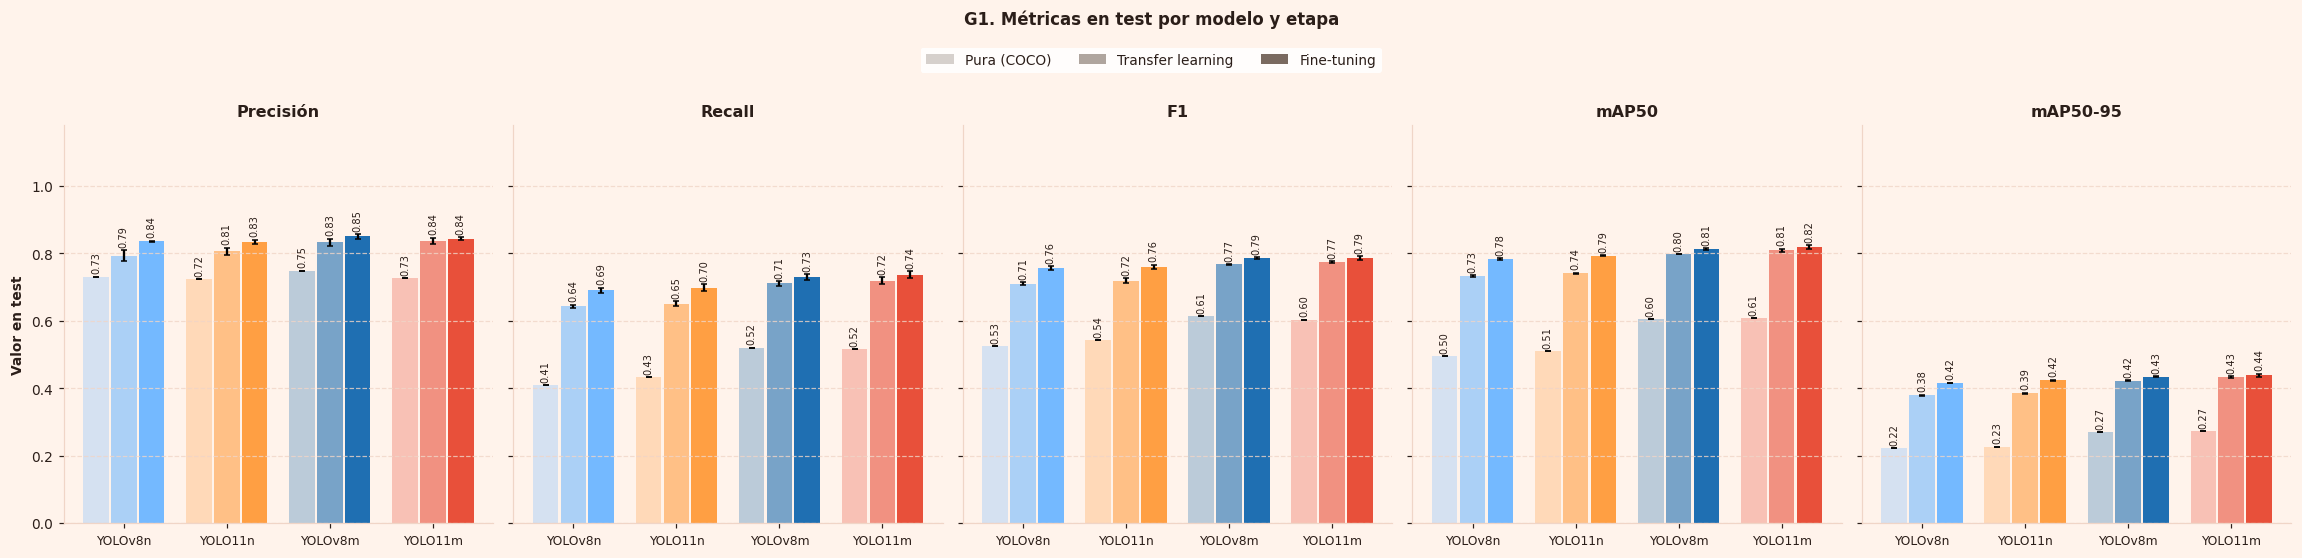

In [ ]:
# G1. Métricas en test: 4 modelos × 3 etapas
fig, ejes = plt.subplots(1, len(METRICAS), figsize=(21, 4.6), sharey=True)
x = np.arange(len(ORDEN))
ancho = 0.27
for ax, metrica in zip(ejes, METRICAS):
    for k, etapa in enumerate(ETAPAS):
        barras = ax.bar(x + (k - 1) * ancho, [medias.loc[(t, etapa), metrica] for t in ORDEN], ancho * 0.92,
                        yerr=[desviaciones.loc[(t, etapa), metrica] for t in ORDEN] if len(SEMILLAS) > 1 else None, capsize=2,
                        color=[COLORES[t] for t in ORDEN], alpha=ALFA_ETAPA[etapa])
        ax.bar_label(barras, fmt='%.2f', fontsize=6.5, padding=2, rotation=90)
    ax.set_xticks(x, ORDEN, fontsize=8)
    ax.set_title(metrica)
    ax.set_ylim(0, 1.18)
    ax.grid(axis='x', visible=False)
ejes[0].set_ylabel('Valor en test')
fig.legend(handles=[Patch(facecolor='#7a6a60', alpha=ALFA_ETAPA[e], label=e) for e in ETAPAS],
           loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.03))
fig.suptitle('G1. Métricas en test por modelo y etapa', y=1.09)
plt.tight_layout()
guardar(fig, 'G1_metricas_por_etapa.png')

### G2. Progresión Pura → Transfer learning → Fine-tuning
**Qué muestra:** el mAP50 (izquierda) y el mAP50-95 (derecha) en test de cada modelo al pasar por las tres etapas. Cada línea es un modelo; el número de la derecha es su valor final.

**Cómo leerla:** la pendiente de cada tramo es lo que aporta esa etapa. Un tramo casi plano significa que esa etapa añade poco.

**Qué buscar:** si las líneas se cruzan (un modelo que empieza peor y termina mejor) y si la distancia entre mAP50 y mAP50-95 cambia:
el mAP50-95 sube más cuando las cajas se ajustan mejor a los bordes de las naranjas, algo que sobre todo aporta el fine-tuning.

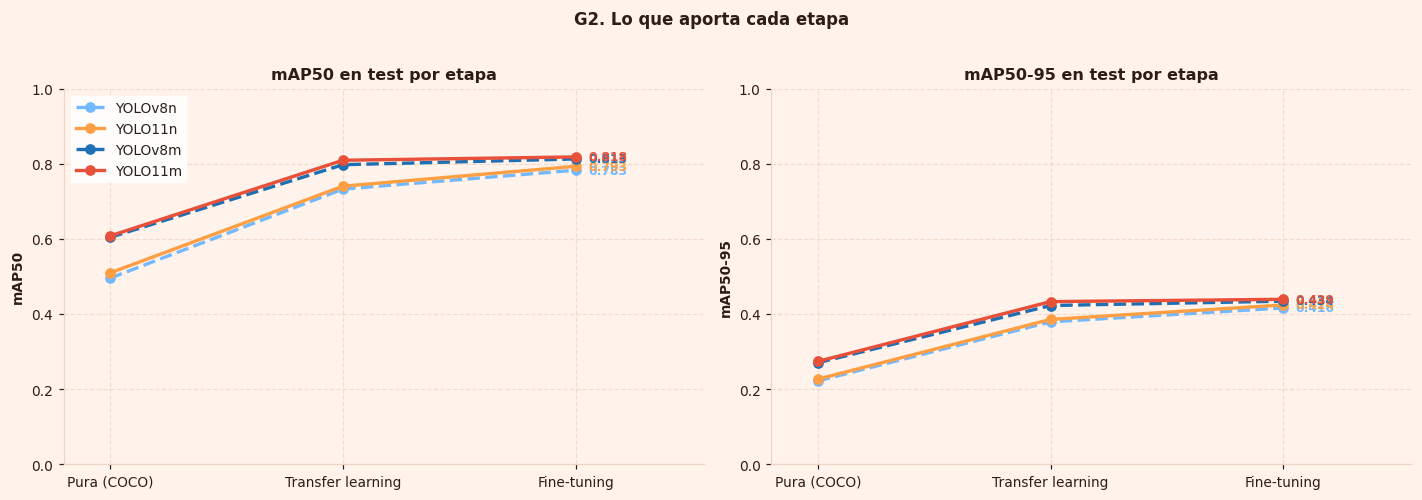

In [ ]:
# G2. Progresión por etapas
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, metrica in zip(ejes, ['mAP50', 'mAP50-95']):
    for tipo in ORDEN:
        valores = [medias.loc[(tipo, e), metrica] for e in ETAPAS]
        ax.plot(range(len(ETAPAS)), valores, marker='o', lw=2.2, ls=LINEA[tipo], color=COLORES[tipo], label=tipo)
        ax.annotate(f'{valores[-1]:.3f}', (len(ETAPAS) - 1, valores[-1]), xytext=(8, 0), textcoords='offset points',
                    va='center', fontsize=8, fontweight='bold', color=COLORES[tipo])
    ax.set_xticks(range(len(ETAPAS)), ETAPAS)
    ax.set_xlim(-0.2, len(ETAPAS) - 0.45)
    ax.set_ylim(0, 1)
    ax.set(title=f'{metrica} en test por etapa', ylabel=metrica)
ejes[0].legend(loc='upper left')
fig.suptitle('G2. Lo que aporta cada etapa', y=1.02)
plt.tight_layout()
guardar(fig, 'G2_progresion_etapas.png')

### G3. Comparación final: los cuatro modelos fine-tuned
**Qué muestra:** la comparación principal del proyecto, con el estilo de la gráfica de v1: las cinco métricas en test de los cuatro modelos después del fine-tuning.

**Cómo leerla:** cada grupo es una métrica y cada barra un modelo. Barra clara vs oscura del mismo tono = efecto del **tamaño**; azul vs naranja del mismo tamaño = efecto de la **generación**.

**Qué buscar:** el modelo con mayor mAP50-95 (la métrica principal). Si la diferencia entre dos modelos es menor que sus barras de error (perfil `completo`),
no se puede afirmar que uno sea mejor. Con una sola semilla, diferencias de ≈ 0.01 pueden deberse al azar.

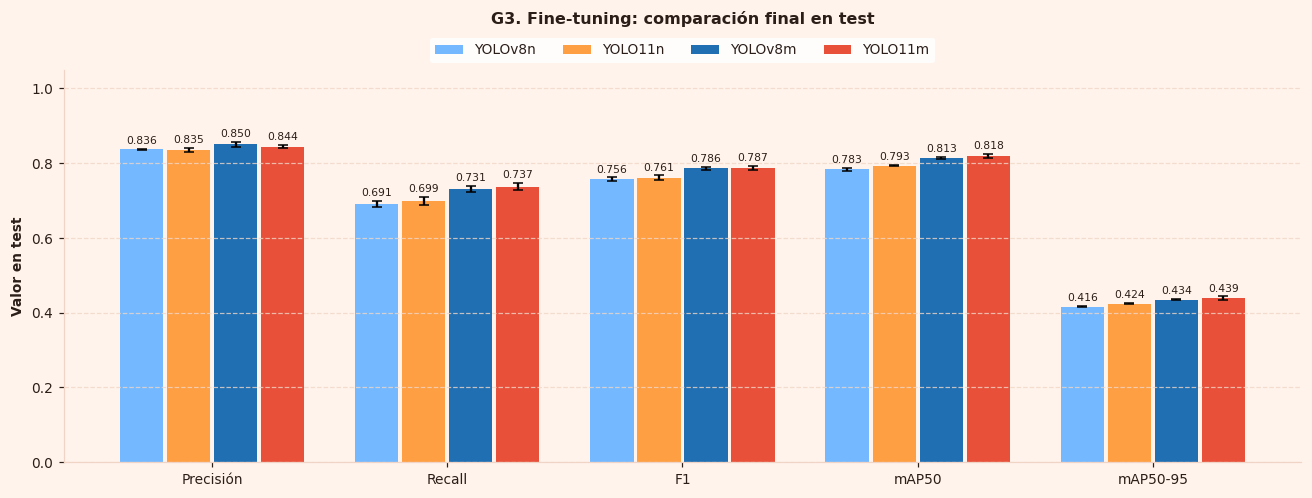

In [ ]:
# G3. Comparación final en test (fine-tuning)
fig, ax = plt.subplots(figsize=(12, 4.6))
x = np.arange(len(METRICAS))
ancho = 0.2
for i, tipo in enumerate(ORDEN):
    g = ft[ft['Modelo'] == tipo][METRICAS]
    barras = ax.bar(x + (i - (len(ORDEN) - 1) / 2) * ancho, g.mean(), ancho * 0.92,
                    yerr=g.std().fillna(0) if len(SEMILLAS) > 1 else None, capsize=3,
                    color=COLORES[tipo], label=tipo)
    ax.bar_label(barras, fmt='%.3f', fontsize=7, padding=2)
ax.set_xticks(x, METRICAS)
ax.set(ylim=(0, 1.05), ylabel='Valor en test')
ax.set_title('G3. Fine-tuning: comparación final en test', pad=30)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=len(ORDEN))
ax.grid(axis='x', visible=False)
plt.tight_layout()
guardar(fig, 'G3_comparacion_final.png')

### G4. *Learning rate* por época
**Qué muestra:** el *learning rate* de los pesos (`lr/pg0` en `results.csv`) al final de cada época, en escala logarítmica. La línea punteada vertical marca el paso de la Fase 1 a la Fase 2.

**Cómo leerla:**
- **Épocas 1–3 (*warmup*):** el LR sube desde casi 0 hasta `lr0`. Como se anota al final de cada época, se ve subir en tres escalones.
- **Resto de la Fase 1:** baja en línea recta (decaimiento lineal) hasta ≈ 11 % de `lr0`.
- **Fase 2:** vuelve a empezar en `lr0 / 10` (casi donde terminó la Fase 1) y baja hasta ≈ 0.3 % de `lr0`. Así, al descongelar el backbone, los pasos ya son pequeños y no se estropean los filtros de COCO.

**Qué buscar:** los modelos del mismo tamaño tienen el mismo `lr0`, así que sus líneas se superponen; solo se separan cuando el *early stopping* corta uno antes.
Los modelos *m* van siempre por debajo de los *n* (`lr0` = 3e-4 frente a 1e-3).

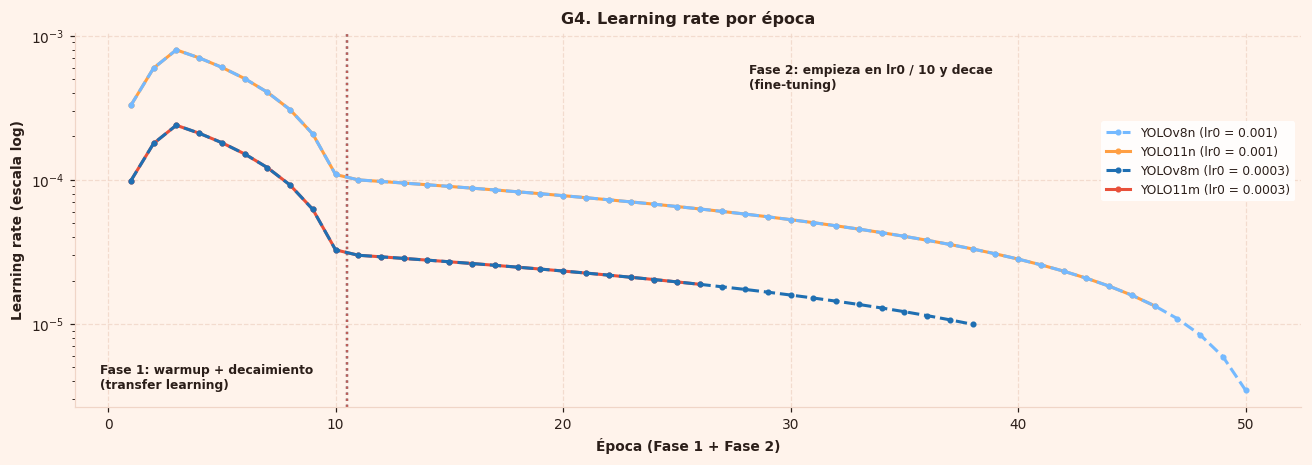

In [ ]:
# G4. Learning rate por época (semilla 0)
fig, ax = plt.subplots(figsize=(12, 4.3))
for tipo in ORDEN:
    h = HISTORIALES[tipo]
    ax.plot(h['epoca_total'], h['lr/pg0'], marker='.', lw=2, ls=LINEA[tipo], color=COLORES[tipo], zorder=CAPA[tipo],
            label=f"{tipo} (lr0 = {MODELOS[tipo]['lr0']:g})")
    ax.axvline((h['fase'] == 1).sum() + 0.5, color=COLORES[tipo], ls=':', alpha=0.7)
ax.set_yscale('log')
ax.text(0.02, 0.05, 'Fase 1: warmup + decaimiento\n(transfer learning)', transform=ax.transAxes, fontsize=8, fontweight='bold')
ax.text(0.55, 0.85, 'Fase 2: empieza en lr0 / 10 y decae\n(fine-tuning)', transform=ax.transAxes, fontsize=8, fontweight='bold')
ax.set(title='G4. Learning rate por época', xlabel='Época (Fase 1 + Fase 2)', ylabel='Learning rate (escala log)')
ax.legend(fontsize=8, loc='upper right', bbox_to_anchor=(1.0, 0.78))
plt.tight_layout()
guardar(fig, 'G4_learning_rate.png')

### G5. mAP en validación por época
**Qué muestra:** el mAP50-95 (izquierda) y el mAP50 (derecha) **en validación** después de cada época. La línea punteada vertical marca el inicio de la Fase 2.
El rombo ◆ marca la época del `best.pt` de la Fase 1 (modelo de transfer learning) y la estrella ★ la del `best.pt` de la Fase 2 (modelo de fine-tuning).

**Cómo leerla:**
- Si el mAP sube al empezar la Fase 2, descongelar el backbone sirvió.
- Si la curva ya es plana al final, el modelo convergió; si todavía subía en la última época, más épocas podrían mejorar el resultado.
- Si el entrenamiento terminó antes de 50 épocas, actuó el *early stopping* (`PACIENCIA` épocas sin mejorar).

**Qué buscar:** qué modelo aprende más rápido (llega antes a un mAP alto) y cuál llega más alto.

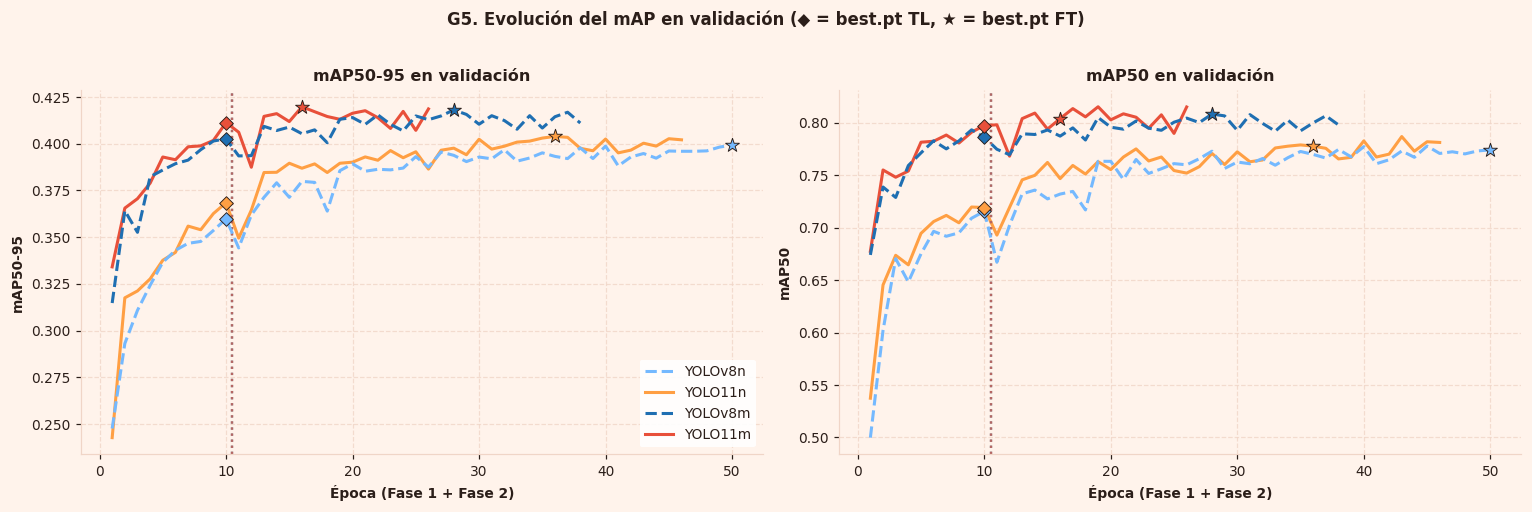

In [ ]:
# G5. mAP en validación por época (semilla 0)
fig, (ax_map, ax_50) = plt.subplots(1, 2, figsize=(14, 4.5))
for tipo in ORDEN:
    h = HISTORIALES[tipo]
    for ax, columna in ((ax_map, 'metrics/mAP50-95(B)'), (ax_50, 'metrics/mAP50(B)')):
        ax.plot(h['epoca_total'], h[columna], lw=2, ls=LINEA[tipo], color=COLORES[tipo], zorder=CAPA[tipo], label=tipo)
        ax.axvline((h['fase'] == 1).sum() + 0.5, color=COLORES[tipo], ls=':', alpha=0.6)
        for fase, marcador in ((1, 'D'), (2, '*')):
            mejor = h.loc[h['fase'] == fase, 'metrics/mAP50-95(B)'].idxmax()   # best.pt = mayor mAP50-95 de la fase
            ax.scatter(h.loc[mejor, 'epoca_total'], h.loc[mejor, columna], marker=marcador, s=90 if marcador == '*' else 40,
                       color=COLORES[tipo], edgecolor=COLOR_TEXTO, linewidth=0.6, zorder=3)
ax_map.set(title='mAP50-95 en validación', xlabel='Época (Fase 1 + Fase 2)', ylabel='mAP50-95')
ax_50.set(title='mAP50 en validación', xlabel='Época (Fase 1 + Fase 2)', ylabel='mAP50')
ax_map.legend()
fig.suptitle('G5. Evolución del mAP en validación (◆ = best.pt TL, ★ = best.pt FT)', y=1.02)
plt.tight_layout()
guardar(fig, 'G5_map_por_epoca.png')

### G6. Pérdidas de entrenamiento y validación
**Qué muestra:** las tres pérdidas (filas: `box_loss`, `cls_loss`, `dfl_loss`) de cada modelo (columnas), en **train** (línea continua) y **validación** (discontinua), época a época.
Es la versión real de la gráfica "train vs val" de v1. La línea punteada vertical marca el inicio de la Fase 2.

**Cómo leerla:** ambas curvas deberían bajar. Con aumento de datos, train puede quedar **por encima** de validación: las imágenes de train
(mosaicos, cambios de color) son más difíciles que las de validación, que no se modifican.

**Qué buscar:**
- **Sobreajuste:** la pérdida de train sigue bajando mientras la de validación sube.
- Un escalón hacia abajo al empezar la Fase 2: al descongelar el backbone la red puede ajustarse mejor.
- Una caída brusca de train en las últimas 10 épocas: se apaga el mosaico (`close_mosaic`) y las imágenes de train se vuelven "normales".

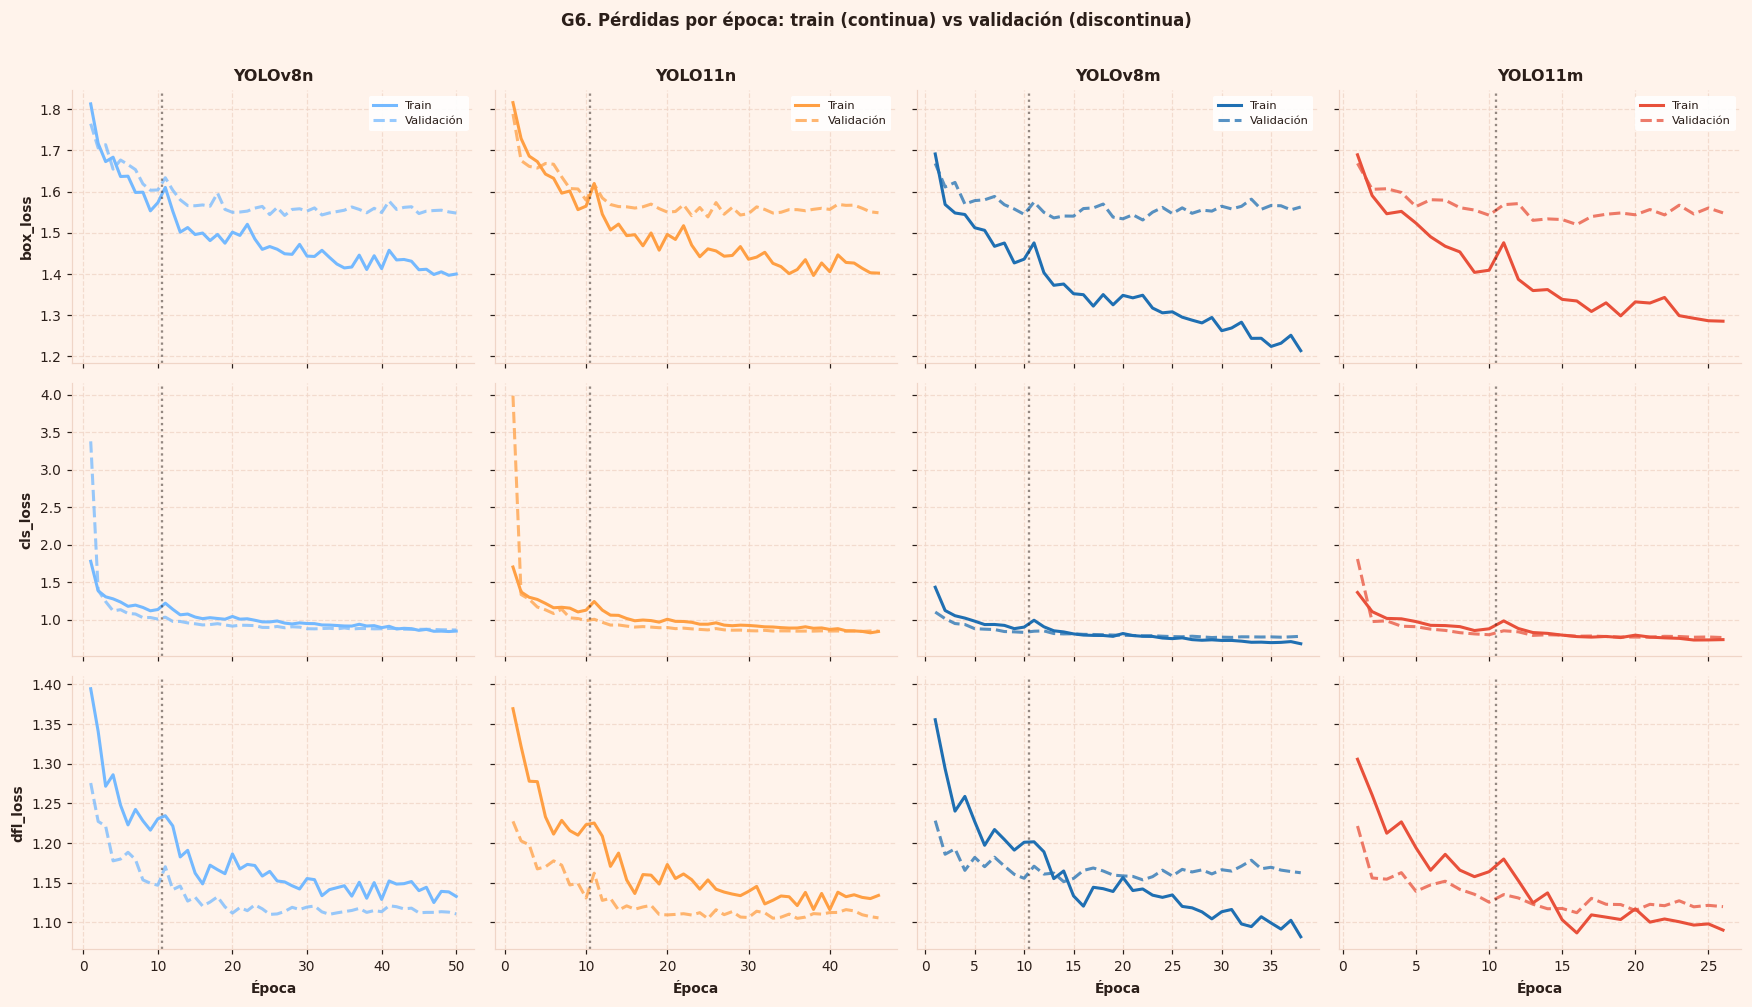

In [ ]:
# G6. Pérdidas de train y validación por época (semilla 0)
PERDIDAS = ['box_loss', 'cls_loss', 'dfl_loss']
fig, ejes = plt.subplots(len(PERDIDAS), len(ORDEN), figsize=(16, 9), sharex='col', sharey='row')
for j, tipo in enumerate(ORDEN):
    h = HISTORIALES[tipo]
    for i, perdida in enumerate(PERDIDAS):
        ax = ejes[i, j]
        ax.plot(h['epoca_total'], h[f'train/{perdida}'], color=COLORES[tipo], lw=2, label='Train')
        ax.plot(h['epoca_total'], h[f'val/{perdida}'], color=COLORES[tipo], lw=2, ls='--', alpha=0.75, label='Validación')
        ax.axvline((h['fase'] == 1).sum() + 0.5, color=COLOR_TEXTO, ls=':', alpha=0.5)
        if i == 0:
            ax.set_title(tipo)
            ax.legend(fontsize=7.5)
        if j == 0:
            ax.set_ylabel(perdida)
        if i == len(PERDIDAS) - 1:
            ax.set_xlabel('Época')
fig.suptitle('G6. Pérdidas por época: train (continua) vs validación (discontinua)', y=1.01)
plt.tight_layout()
guardar(fig, 'G6_perdidas_train_val.png')

### G7. Pérdidas finales de validación
**Qué muestra:** las pérdidas de **validación** de cada modelo fine-tuned en la época de su `best.pt` (estilo de la gráfica de pérdidas de v1).

**Cómo leerla:** más bajo es mejor. Se comparan modelos **dentro** de cada tipo de pérdida; las tres pérdidas tienen escalas distintas y no se comparan entre sí.

**Qué buscar:** `box_loss` baja ↔ cajas mejor ubicadas (se refleja en el mAP50-95); `cls_loss` baja ↔ distingue mejor naranja de fondo (precisión y recall);
`dfl_loss` baja ↔ bordes más precisos.

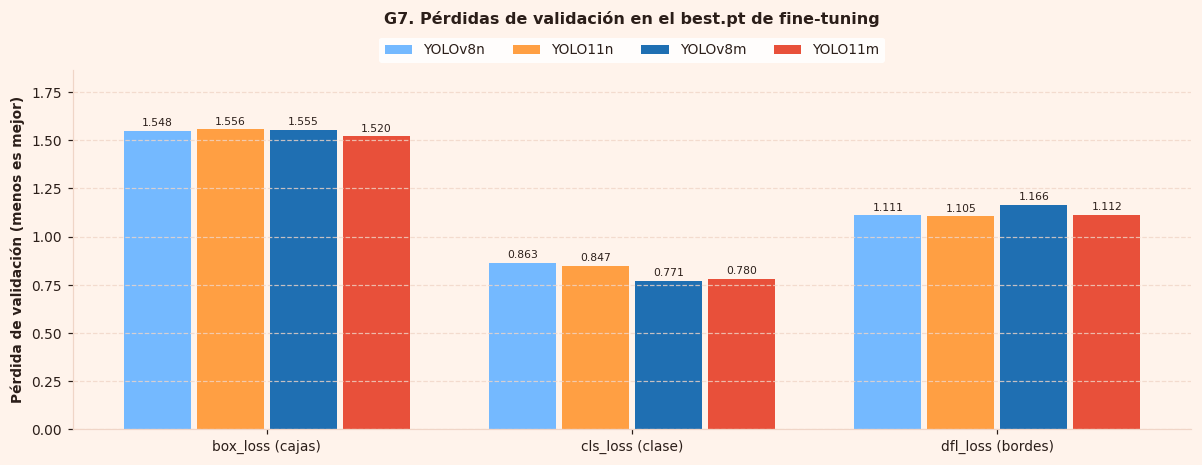

In [ ]:
# G7. Pérdidas de validación en la época del best.pt de fine-tuning (semilla 0)
finales = {}
for tipo in ORDEN:
    h = HISTORIALES[tipo]
    mejor = h.loc[h['fase'] == 2, 'metrics/mAP50-95(B)'].idxmax()
    finales[tipo] = [h.loc[mejor, f'val/{p}'] for p in PERDIDAS]

fig, ax = plt.subplots(figsize=(11, 4.3))
x = np.arange(len(PERDIDAS))
ancho = 0.2
for i, tipo in enumerate(ORDEN):
    barras = ax.bar(x + (i - (len(ORDEN) - 1) / 2) * ancho, finales[tipo], ancho * 0.92, color=COLORES[tipo], label=tipo)
    ax.bar_label(barras, fmt='%.3f', fontsize=7, padding=2)
ax.set_xticks(x, ['box_loss (cajas)', 'cls_loss (clase)', 'dfl_loss (bordes)'])
ax.set(ylabel='Pérdida de validación (menos es mejor)', ylim=(0, max(max(v) for v in finales.values()) * 1.2))
ax.set_title('G7. Pérdidas de validación en el best.pt de fine-tuning', pad=30)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=len(ORDEN))
ax.grid(axis='x', visible=False)
plt.tight_layout()
guardar(fig, 'G7_perdidas_finales.png')

### G8. Matrices de confusión
**Qué muestra:** la matriz de confusión de detección (sección 5.7) de cada modelo (columnas) en cada etapa (filas), contando cajas en test con el umbral de confianza de validación.
En v1 esta gráfica se dibujaba a partir de la precisión y el recall; aquí se **cuentan** las cajas de verdad.

**Cómo leerla:** fila *Real: naranja* = TP (encontradas) y FN (perdidas); fila *Real: fondo* = FP (falsas alarmas).
El color de cada casilla es su cantidad dividida entre el número de naranjas reales. En el título están la precisión TP / (TP + FP) y el recall TP / (TP + FN).

**Qué buscar:** en la etapa Pura suele haber muchos FN (COCO no reconoce naranjas pequeñas, verdes o tapadas por hojas).
¿El entrenamiento reduce sobre todo los FN (más recall) o los FP (más precisión)? ¿Qué modelo deja menos naranjas sin detectar?

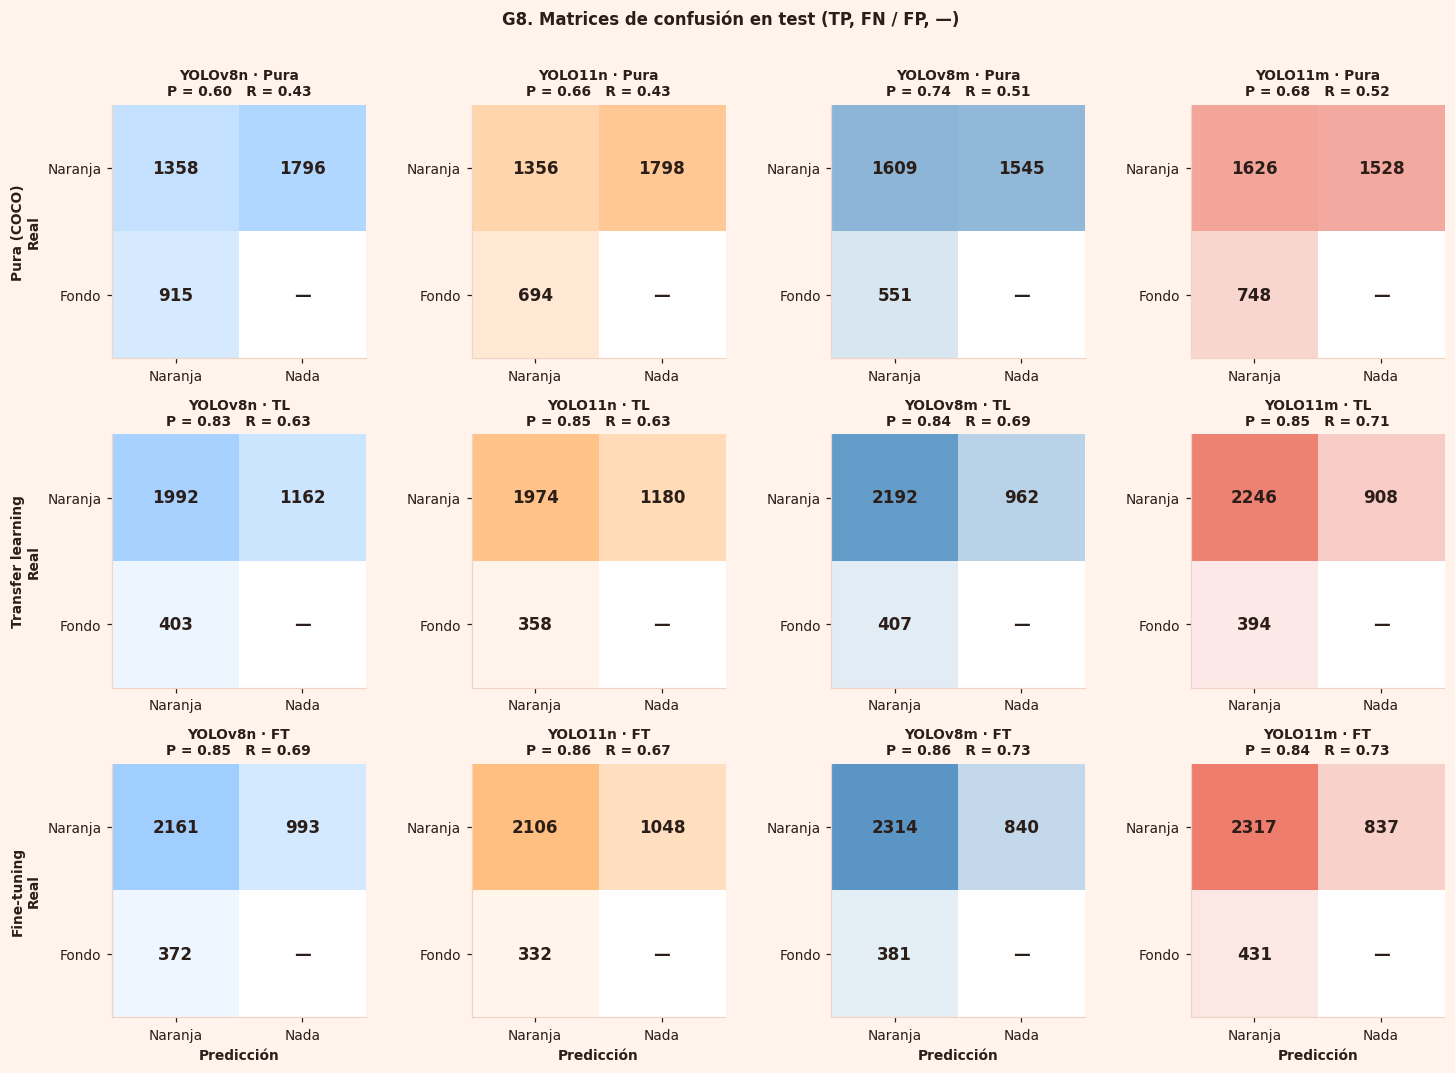

In [ ]:
# G8. Matrices de confusión: filas = etapas, columnas = modelos
fig, ejes = plt.subplots(len(ETAPAS), len(ORDEN), figsize=(3.4 * len(ORDEN), 3.2 * len(ETAPAS)))
for i, etapa in enumerate(ETAPAS):
    for j, tipo in enumerate(ORDEN):
        ax = ejes[i, j]
        f = CONFUSION[(CONFUSION['Modelo'] == tipo) & (CONFUSION['Etapa'] == etapa)].iloc[0]
        reales = max(f['TP'] + f['FN'], 1)
        cuentas = np.array([[f['TP'], f['FN']], [f['FP'], 0]])
        mapa = LinearSegmentedColormap.from_list('', ['#FFFFFF', COLORES[tipo]])
        ax.imshow(cuentas / reales, cmap=mapa, vmin=0, vmax=1)
        for (fila, col), valor in np.ndenumerate(cuentas):
            texto = '—' if (fila, col) == (1, 1) else f'{int(valor)}'
            ax.text(col, fila, texto, ha='center', va='center', fontsize=11, fontweight='bold')
        ax.set_xticks([0, 1], ['Naranja', 'Nada'])
        ax.set_yticks([0, 1], ['Naranja', 'Fondo'])
        ax.grid(False)
        ax.set_title(f"{tipo} · {ETAPA_CORTA[etapa]}\nP = {f['Precisión']:.2f}   R = {f['Recall']:.2f}", fontsize=9)
        if i == len(ETAPAS) - 1:
            ax.set_xlabel('Predicción')
        if j == 0:
            ax.set_ylabel(f'{etapa}\nReal')
fig.suptitle('G8. Matrices de confusión en test (TP, FN / FP, —)', y=1.01)
plt.tight_layout()
guardar(fig, 'G8_matrices_confusion.png')

### G9. Curvas precisión–recall y F1–confianza (fine-tuning)
**Qué muestra:** a la izquierda, la curva **precisión–recall** (IoU 0.5) de cada modelo fine-tuned en test; su área es el AP50, que con una sola clase es el mAP50 (en la leyenda).
A la derecha, el **F1 según el umbral de confianza**; el punto marca el umbral elegido en validación.

**Cómo leerla:**
- PR: cuanto más arriba y a la derecha, mejor (alta precisión aun con recall alto). La curva cae al final: para encontrar las últimas naranjas
  (las difíciles) hay que aceptar detecciones poco seguras y aparecen falsas alarmas.
- F1: con un umbral muy bajo hay muchos FP; con uno muy alto, muchos FN. El máximo es el mejor equilibrio. Una meseta ancha significa que el modelo es poco sensible a la elección del umbral.

**Qué buscar:** el recall máximo al que llega cada curva (naranjas que el modelo nunca encuentra) y si el punto de validación cae cerca del máximo de F1 en test
(si es así, el umbral elegido en validación generaliza bien).

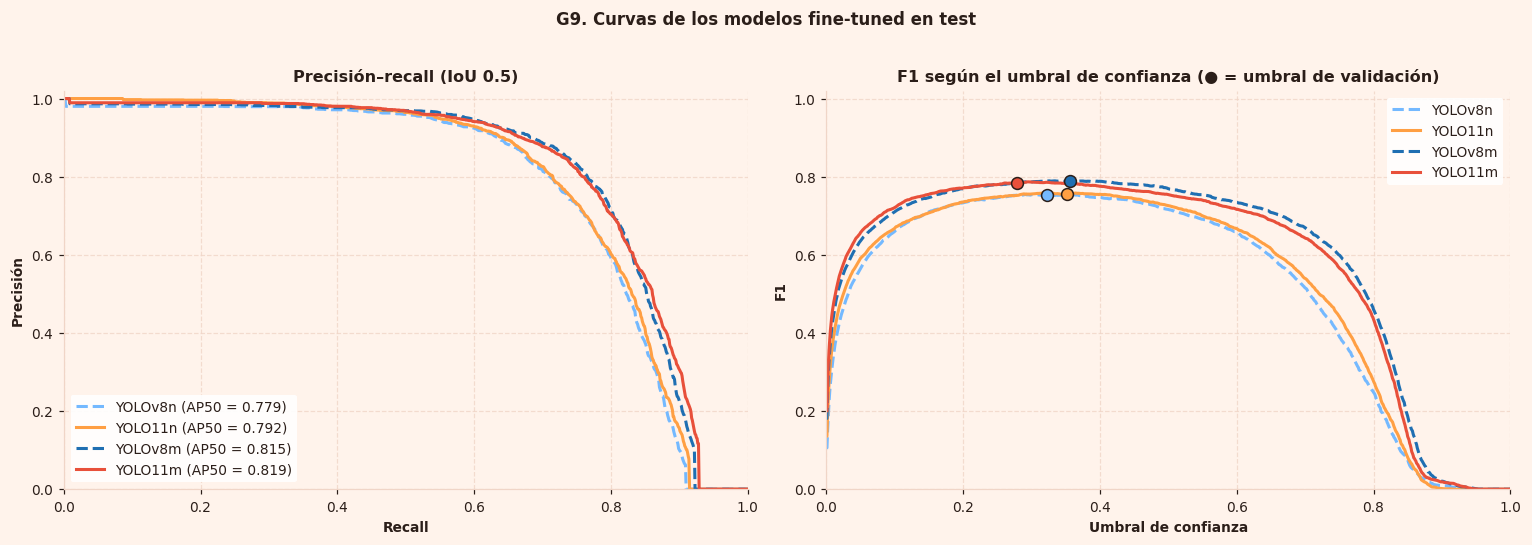

In [ ]:
# G9. Curvas PR y F1-confianza en test (fine-tuning, mejor semilla)
fig, (ax_pr, ax_f1) = plt.subplots(1, 2, figsize=(14, 4.8))
for tipo in ORDEN:
    curvas = CURVAS[(tipo, 'Fine-tuning', semilla_de(tipo, 'Fine-tuning'))]
    fila = fila_de(tipo, 'Fine-tuning')
    ax_pr.plot(curvas['eje'], curvas['pr'], lw=2, ls=LINEA[tipo], color=COLORES[tipo], label=f"{tipo} (AP50 = {fila['mAP50']:.3f})")
    ax_f1.plot(curvas['eje'], curvas['f1'], lw=2, ls=LINEA[tipo], color=COLORES[tipo], label=tipo)
    umbral = fila['Umbral conf. (val)']
    ax_f1.scatter(umbral, np.interp(umbral, curvas['eje'], curvas['f1']), s=60, color=COLORES[tipo], edgecolor=COLOR_TEXTO, zorder=3)
ax_pr.set(title='Precisión–recall (IoU 0.5)', xlabel='Recall', ylabel='Precisión', xlim=(0, 1), ylim=(0, 1.02))
ax_f1.set(title='F1 según el umbral de confianza (● = umbral de validación)', xlabel='Umbral de confianza', ylabel='F1', xlim=(0, 1), ylim=(0, 1.02))
ax_pr.legend(loc='lower left')
ax_f1.legend(loc='upper right')
fig.suptitle('G9. Curvas de los modelos fine-tuned en test', y=1.02)
plt.tight_layout()
guardar(fig, 'G9_curvas_pr_f1.png')

### G10. Curvas precisión–recall por etapa
**Qué muestra:** para cada modelo, la curva precisión–recall en test de sus tres etapas (pálida = Pura, media = TL, llena = FT). El área bajo cada curva es su AP50.

**Cómo leerla:** el área que se gana entre dos curvas es la mejora de esa etapa. Si la curva de la etapa Pura se corta muy a la izquierda,
el modelo de COCO encuentra pocas naranjas aunque se le permita usar detecciones de muy baja confianza.

**Qué buscar:** si el transfer learning ya acerca la curva a la del fine-tuning (el backbone de COCO bastaba) o si la mejora grande llega al descongelar el backbone.

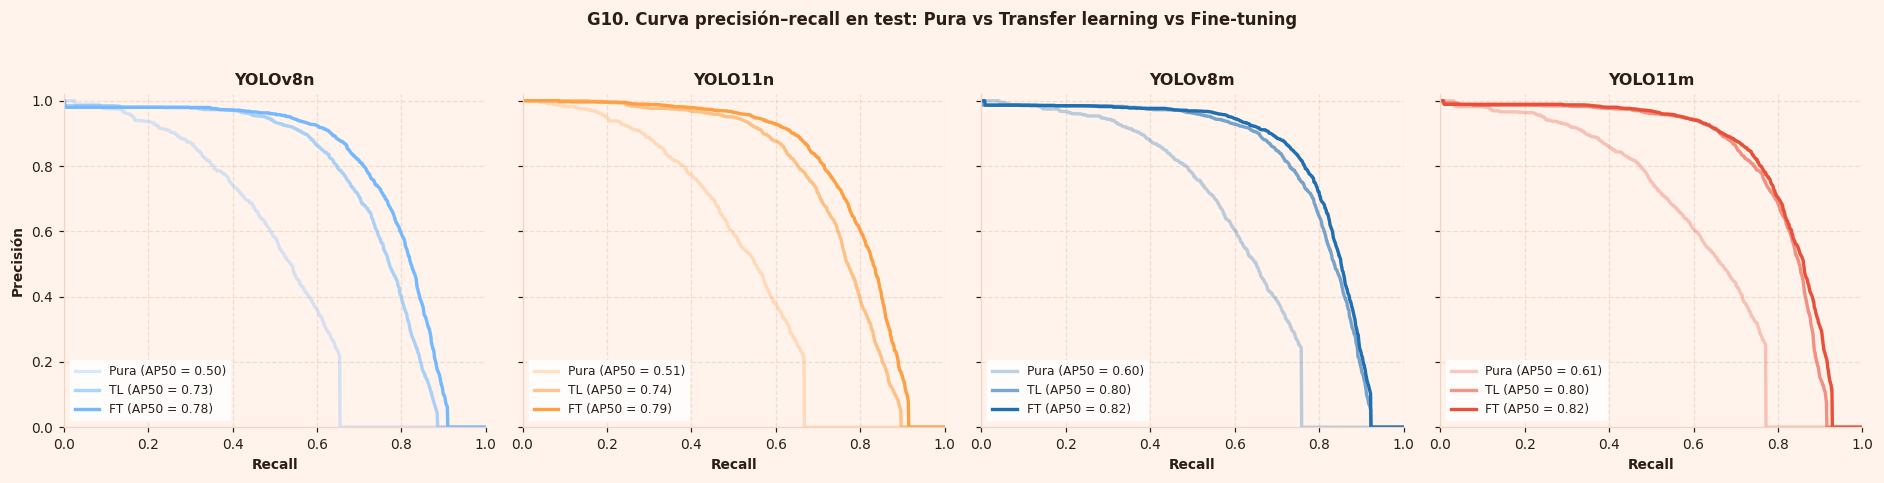

In [ ]:
# G10. Curvas PR de las tres etapas de cada modelo
fig, ejes = plt.subplots(1, len(ORDEN), figsize=(4.3 * len(ORDEN), 4.2), sharey=True)
for ax, tipo in zip(ejes, ORDEN):
    for etapa in ETAPAS:
        curvas = CURVAS[(tipo, etapa, semilla_de(tipo, etapa))]
        ax.plot(curvas['eje'], curvas['pr'], lw=2.2, color=COLORES[tipo], alpha=ALFA_ETAPA[etapa],
                label=f"{ETAPA_CORTA[etapa]} (AP50 = {fila_de(tipo, etapa)['mAP50']:.2f})")
    ax.set(title=tipo, xlabel='Recall', xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc='lower left', fontsize=8)
ejes[0].set_ylabel('Precisión')
fig.suptitle('G10. Curva precisión–recall en test: Pura vs Transfer learning vs Fine-tuning', y=1.03)
plt.tight_layout()
guardar(fig, 'G10_curvas_pr_por_etapa.png')

### G11. Velocidad vs precisión
**Qué muestra:** cada modelo fine-tuned como un punto: latencia por imagen en el eje x y mAP50-95 en test en el eje y. El tamaño del punto es proporcional al número de parámetros.
La línea vertical marca 33 ms (≈ 30 FPS, tiempo real). Se usa la latencia de GPU si hay GPU; si no, la de CPU.

**Cómo leerla:** lo ideal es arriba a la izquierda (preciso y rápido). Un modelo está **dominado** si otro es a la vez más rápido y más preciso.
Los modelos no dominados, unidos por la línea gris, forman la **frontera de Pareto**: entre ellos no hay un "mejor" absoluto; depende de si importa más la velocidad o la precisión.

**Qué buscar:** cuánto mAP se gana por cada ms extra al pasar de *n* a *m*, y si YOLO11 domina a YOLOv8 del mismo tamaño.
Si el modelo se va a usar sin GPU, cambia `columna` a `'CPU (ms/img)'` y repite la gráfica.

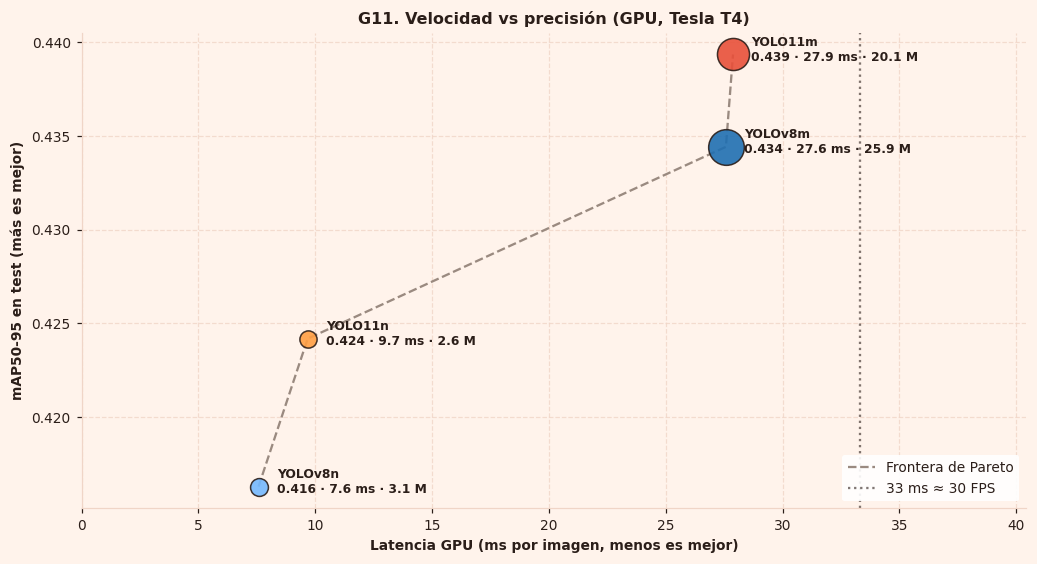

In [ ]:
# G11. Velocidad vs precisión (fine-tuning)
columna = 'GPU (ms/img)' if 'GPU (ms/img)' in velocidad else 'CPU (ms/img)'
puntos = pd.DataFrame({'latencia': velocidad.loc[ORDEN, columna],
                       'map': medias.xs('Fine-tuning', level='Etapa').loc[ORDEN, 'mAP50-95'],
                       'params': velocidad.loc[ORDEN, 'Parámetros (M)']})
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for tipo, p in puntos.iterrows():
    ax.scatter(p['latencia'], p['map'], s=80 + 18 * p['params'], color=COLORES[tipo], edgecolor=COLOR_TEXTO, alpha=0.9, zorder=3)
    ax.annotate(f"{tipo}\n{p['map']:.3f} · {p['latencia']:.1f} ms · {p['params']:.1f} M", (p['latencia'], p['map']),
                xytext=(12, -4), textcoords='offset points', fontsize=8, fontweight='bold')
# Frontera de Pareto: recorriendo de más rápido a más lento, se queda cada modelo que mejora el mAP de todos los anteriores
frontera, mejor_map = [], -1
for tipo, p in puntos.sort_values('latencia').iterrows():
    if p['map'] > mejor_map:
        frontera.append(tipo)
        mejor_map = p['map']
ax.plot(puntos.loc[frontera, 'latencia'], puntos.loc[frontera, 'map'], color='#9a8a80', ls='--', lw=1.5, zorder=2, label='Frontera de Pareto')
ax.axvline(1000 / 30, color=COLOR_TEXTO, ls=':', alpha=0.6, label='33 ms ≈ 30 FPS')
ax.set_xlim(0, puntos['latencia'].max() * 1.45)
ax.set(title=f"G11. Velocidad vs precisión ({columna.split()[0]}, {velocidad['GPU usada'].iloc[0]})",
       xlabel=f'Latencia {columna.split()[0]} (ms por imagen, menos es mejor)', ylabel='mAP50-95 en test (más es mejor)')
ax.legend(loc='lower right')
plt.tight_layout()
guardar(fig, 'G11_velocidad_vs_precision.png')

### G12. mAP50 por entorno
**Qué muestra:** el mAP50 en test de cada modelo fine-tuned (columnas) en cada entorno de captura (filas). Junto al entorno aparece cuántas imágenes de test tiene;
los entornos con menos de 30 imágenes llevan un asterisco (poco fiables).

**Cómo leerla:** colores más intensos = mejor detección. Comparar filas muestra qué condiciones son difíciles; comparar columnas, qué modelo es más robusto.

**Qué buscar:** las condiciones difíciles (noche, atardecer, interior) y si el modelo más grande ayuda justo ahí.
No saques conclusiones de las filas con asterisco: con 1–8 imágenes una sola foto difícil cambia el resultado.

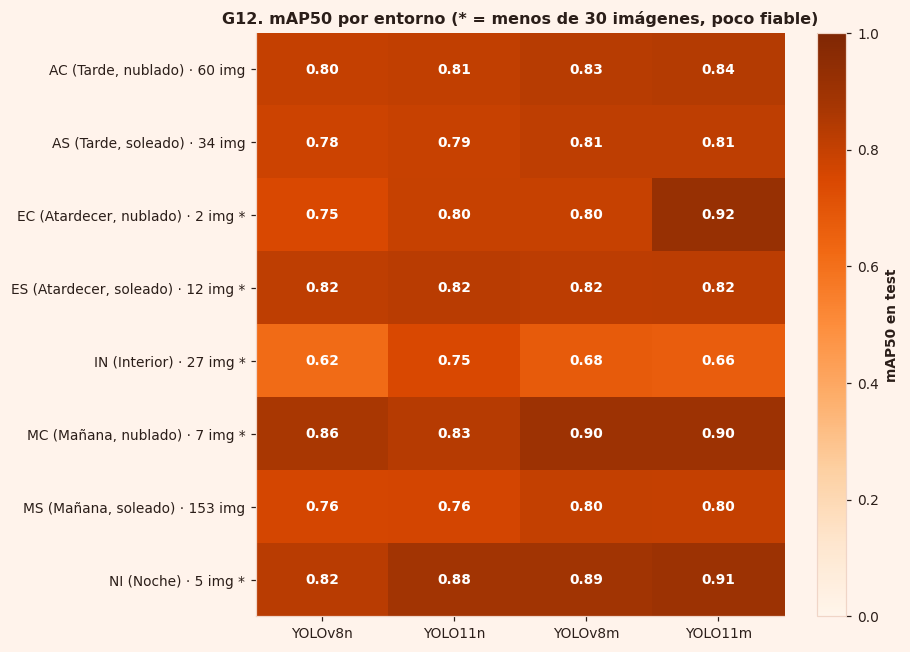

In [ ]:
# G12. Mapa de calor del mAP50 por entorno (fine-tuning)
datos = por_entorno.reset_index()
etiquetas = [f"{e} · {n} img{'' if fiable else ' *'}" for e, n, fiable in zip(datos['Entorno'], datos['Imágenes'], datos['Fiable'])]
matriz = datos[ORDEN].to_numpy(dtype=float)
fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(datos) + 1.6))
imagen = ax.imshow(matriz, cmap='Oranges', vmin=0, vmax=1, aspect='auto')
for (i, j), valor in np.ndenumerate(matriz):
    ax.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=9, fontweight='bold',
            color='white' if valor > 0.6 else COLOR_TEXTO)
ax.set_xticks(range(len(ORDEN)), ORDEN)
ax.set_yticks(range(len(etiquetas)), etiquetas)
ax.grid(False)
fig.colorbar(imagen, ax=ax, label='mAP50 en test')
ax.set_title('G12. mAP50 por entorno (* = menos de 30 imágenes, poco fiable)')
plt.tight_layout()
guardar(fig, 'G12_map50_por_entorno.png')

### G13. Estructura de los modelos y parámetros de entrenamiento
**Qué muestra:** un diagrama (estilo v1) con los cuatro modelos y sus datos **medidos** en la sección 5.9: bloques, capas del backbone, parámetros, GFLOPs y tamaño del archivo.
En v1 estos números se escribían a mano; aquí salen de los modelos entrenados. Abajo, los hiperparámetros reales del entrenamiento.

**Cómo leerla:** de arriba abajo es el recorrido de una imagen: entra una foto de 640 × 640, cada modelo la procesa y sale una lista de cajas con confianza.

**Qué buscar:** relaciona el tamaño con la precisión de G3: el modelo *m* tiene ≈ 8 veces más parámetros que el *n*, pero no es 8 veces mejor (rendimientos decrecientes).

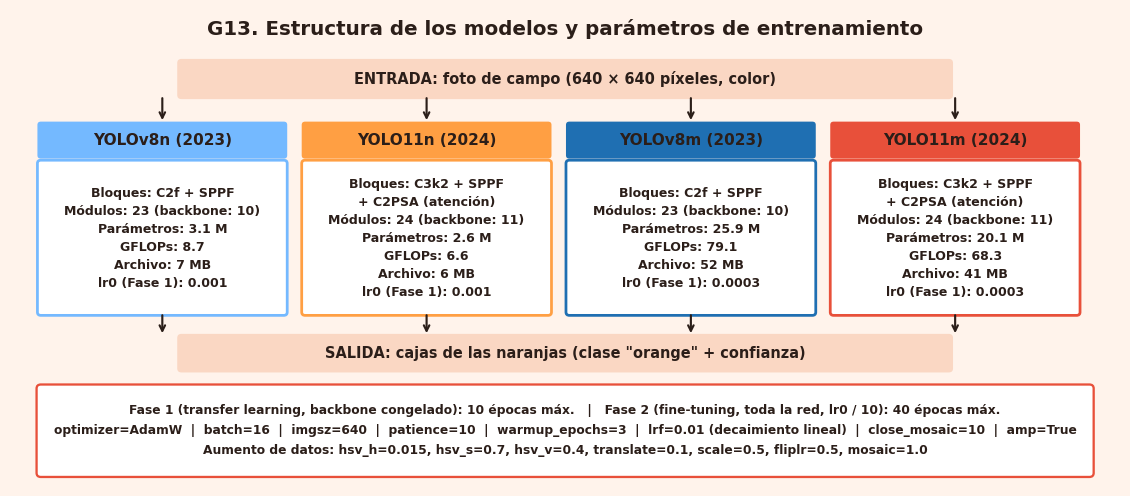

In [ ]:
# G13. Diagrama de los modelos con datos medidos
DESCRIPCION = {'YOLOv8': ('2023', 'C2f + SPPF'), 'YOLO11': ('2024', 'C3k2 + SPPF\n+ C2PSA (atención)')}
fig, ax = plt.subplots(figsize=(13, 5.6))
ax.set_xlim(0, 13)
ax.set_ylim(-0.3, 5.6)
ax.axis('off')
ax.text(6.5, 5.3, 'G13. Estructura de los modelos y parámetros de entrenamiento', ha='center', fontsize=13, fontweight='bold')
ax.add_patch(FancyBboxPatch((2.0, 4.55), 9.0, 0.4, boxstyle='round,pad=0.05', facecolor='#FAD7C3', edgecolor='none'))
ax.text(6.5, 4.75, f'ENTRADA: foto de campo ({IMGSZ} × {IMGSZ} píxeles, color)', ha='center', va='center', fontsize=9.5, fontweight='bold')
ancho_caja = 2.85
for k, tipo in enumerate(ORDEN):
    x0 = 0.35 + k * 3.1
    centro = x0 + ancho_caja / 2
    generacion, bloques = DESCRIPCION['YOLO11' if tipo.startswith('YOLO11') else 'YOLOv8']
    v = velocidad.loc[tipo]
    ax.annotate('', xy=(centro, 4.2), xytext=(centro, 4.55), arrowprops=dict(arrowstyle='->', color=COLOR_TEXTO, lw=1.4))
    ax.add_patch(FancyBboxPatch((x0, 3.8), ancho_caja, 0.38, boxstyle='round,pad=0.04', facecolor=COLORES[tipo], edgecolor='none'))
    ax.text(centro, 3.99, f'{tipo} ({generacion})', ha='center', va='center', fontsize=10, fontweight='bold')
    ax.add_patch(FancyBboxPatch((x0, 1.85), ancho_caja, 1.85, boxstyle='round,pad=0.04', facecolor='white', edgecolor=COLORES[tipo], lw=1.8))
    texto = (f'Bloques: {bloques}\n'
             f"Módulos: {int(v['Bloques'])} (backbone: {int(v['Backbone'])})\n"
             f"Parámetros: {v['Parámetros (M)']:.1f} M\n"
             f"GFLOPs: {v['GFLOPs']:.1f}\n"
             f"Archivo: {v['Archivo (MB)']:.0f} MB\n"
             f"lr0 (Fase 1): {MODELOS[tipo]['lr0']:g}")
    ax.text(centro, 2.775, texto, ha='center', va='center', fontsize=8.2, fontweight='bold', linespacing=1.5)
    ax.annotate('', xy=(centro, 1.55), xytext=(centro, 1.85), arrowprops=dict(arrowstyle='->', color=COLOR_TEXTO, lw=1.4))
ax.add_patch(FancyBboxPatch((2.0, 1.15), 9.0, 0.38, boxstyle='round,pad=0.05', facecolor='#FAD7C3', edgecolor='none'))
ax.text(6.5, 1.34, 'SALIDA: cajas de las naranjas (clase "orange" + confianza)', ha='center', va='center', fontsize=9.5, fontweight='bold')
ax.add_patch(FancyBboxPatch((0.35, -0.15), 12.3, 1.05, boxstyle='round,pad=0.05', facecolor='white', edgecolor=COLORES['YOLO11m'], lw=1.5))
ax.text(6.5, 0.38, f'Fase 1 (transfer learning, backbone congelado): {EPOCAS_FASE1} épocas máx.   |   '
        f'Fase 2 (fine-tuning, toda la red, lr0 / 10): {EPOCAS_FASE2} épocas máx.\n'
        f'optimizer={OPTIMIZADOR}  |  batch={BATCH}  |  imgsz={IMGSZ}  |  patience={PACIENCIA}  |  warmup_epochs=3  |  '
        f'lrf=0.01 (decaimiento lineal)  |  close_mosaic=10  |  amp=True\n'
        'Aumento de datos: ' + ', '.join(f'{k}={v}' for k, v in AUMENTACION.items()),
        ha='center', va='center', fontsize=8, fontweight='bold', linespacing=1.7)
guardar(fig, 'G13_estructura_modelos.png')

### G14. Detecciones de los cuatro modelos
**Qué muestra:** las mismas imágenes de test (una de interior si hay) con las naranjas reales (primera columna) y las detectadas por cada modelo fine-tuned con su umbral de validación.
El número entre paréntesis es la cantidad de cajas.

**Cómo leerla:** compara cada columna con la primera: cajas de más son FP, naranjas sin caja son FN.

**Qué buscar:** qué naranjas se pierden (pequeñas, tapadas, verdes, a contraluz) y si los modelos *m* las encuentran.

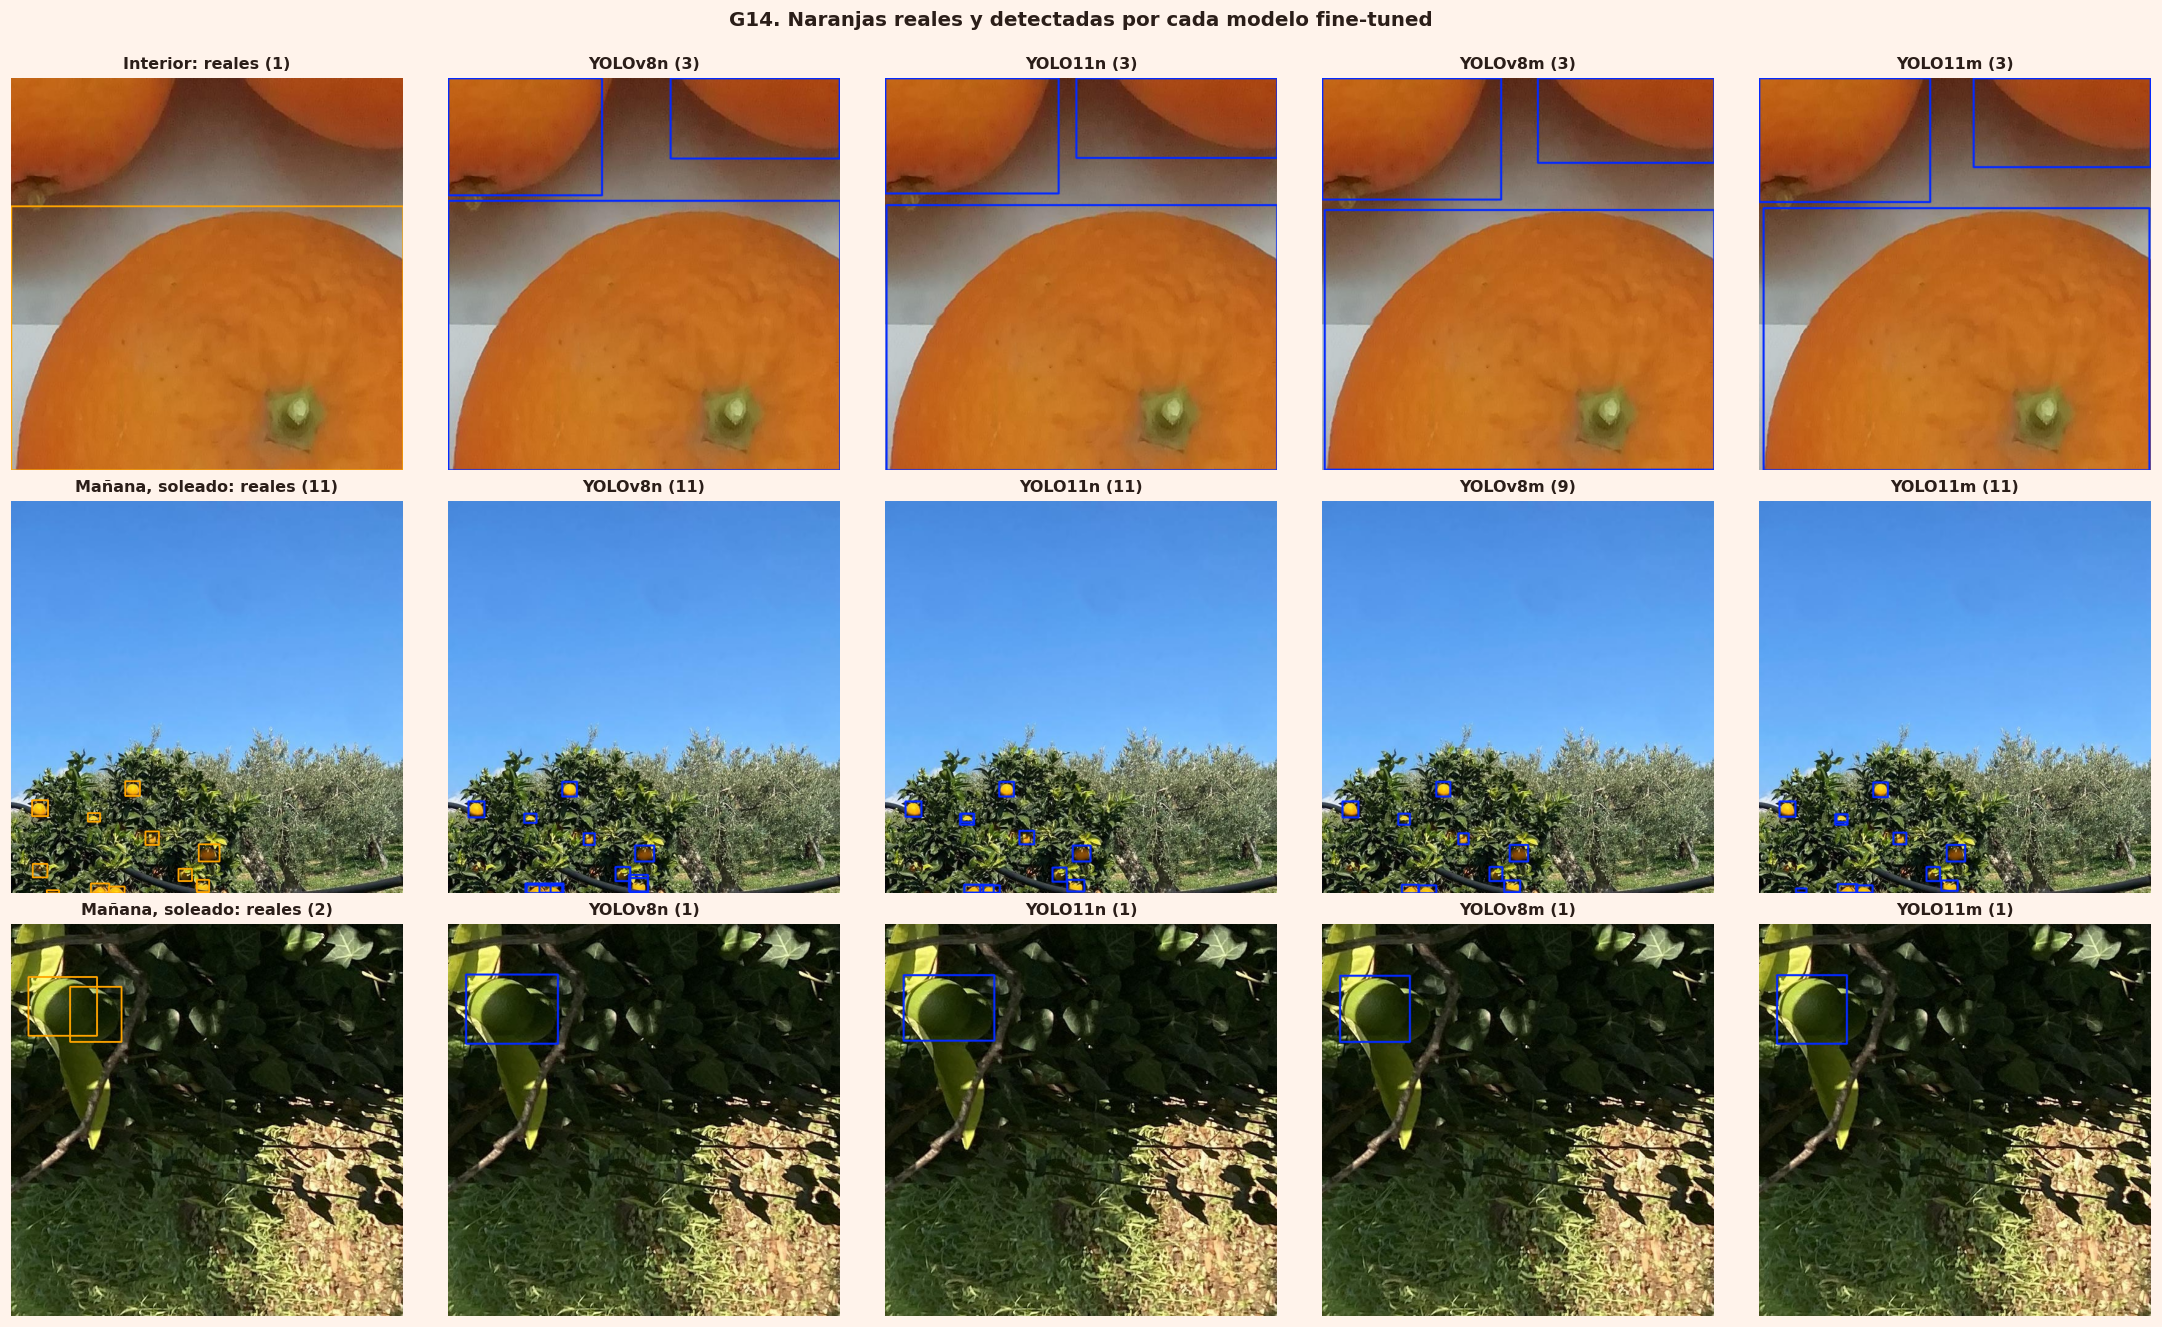

In [ ]:
# G14. Comparación visual de los modelos fine-tuned sobre las mismas imágenes de test (una de interior si hay)
modelos_finales = {tipo: cargar_modelo(pesos) for tipo, pesos in PESOS_MEJORES.items()}
interior = test_tabla[test_tabla['entorno'] == 'IN']['archivo'].sample(frac=1, random_state=0).head(1)
otras = test_tabla[test_tabla['entorno'] != 'IN']['archivo'].sample(frac=1, random_state=0).head(3 - len(interior))
muestra = list(interior) + list(otras)

fig, ejes = plt.subplots(len(muestra), len(MODELOS) + 1, figsize=(4 * (len(MODELOS) + 1), 4 * len(muestra)), squeeze=False)
for fila, archivo in enumerate(muestra):
    imagen = cv2.imread(str(ruta_imagen(archivo, 'test')))
    reales = imagen.copy()
    cajas = leer_cajas(archivo, 'test', imagen.shape[1], imagen.shape[0])
    for x1, y1, x2, y2 in cajas.astype(int):
        cv2.rectangle(reales, (x1, y1), (x2, y2), (0, 165, 255), 2)
    ejes[fila, 0].imshow(a_rgb(reales))
    ejes[fila, 0].set_title(f'{ENTORNOS[archivo[:2]]}: reales ({len(cajas)})')
    for col, (tipo, modelo) in enumerate(modelos_finales.items(), start=1):
        r = modelo.predict(imagen, conf=float(MEJOR.loc[tipo, 'Umbral conf. (val)']), imgsz=IMGSZ, verbose=False)[0]
        ejes[fila, col].imshow(a_rgb(r.plot(labels=False, conf=False)))
        ejes[fila, col].set_title(f'{tipo} ({len(r.boxes)})')
for ax in ejes.flat:
    ax.axis('off')
fig.suptitle('G14. Naranjas reales y detectadas por cada modelo fine-tuned', y=1.0, fontsize=13)
plt.tight_layout()
guardar(fig, 'G14_comparacion_visual.png')

### G15. Detecciones en las tres etapas
**Qué muestra:** una misma imagen de test con muchas naranjas: las reales (primera columna) y las detectadas por cada modelo (filas) en cada etapa (columnas).

**Cómo leerla:** de izquierda a derecha se ve el efecto de cada etapa sobre las mismas naranjas.

**Qué buscar:** la etapa Pura suele detectar solo las naranjas grandes y bien visibles; el transfer learning y el fine-tuning deberían recuperar las pequeñas y las tapadas.

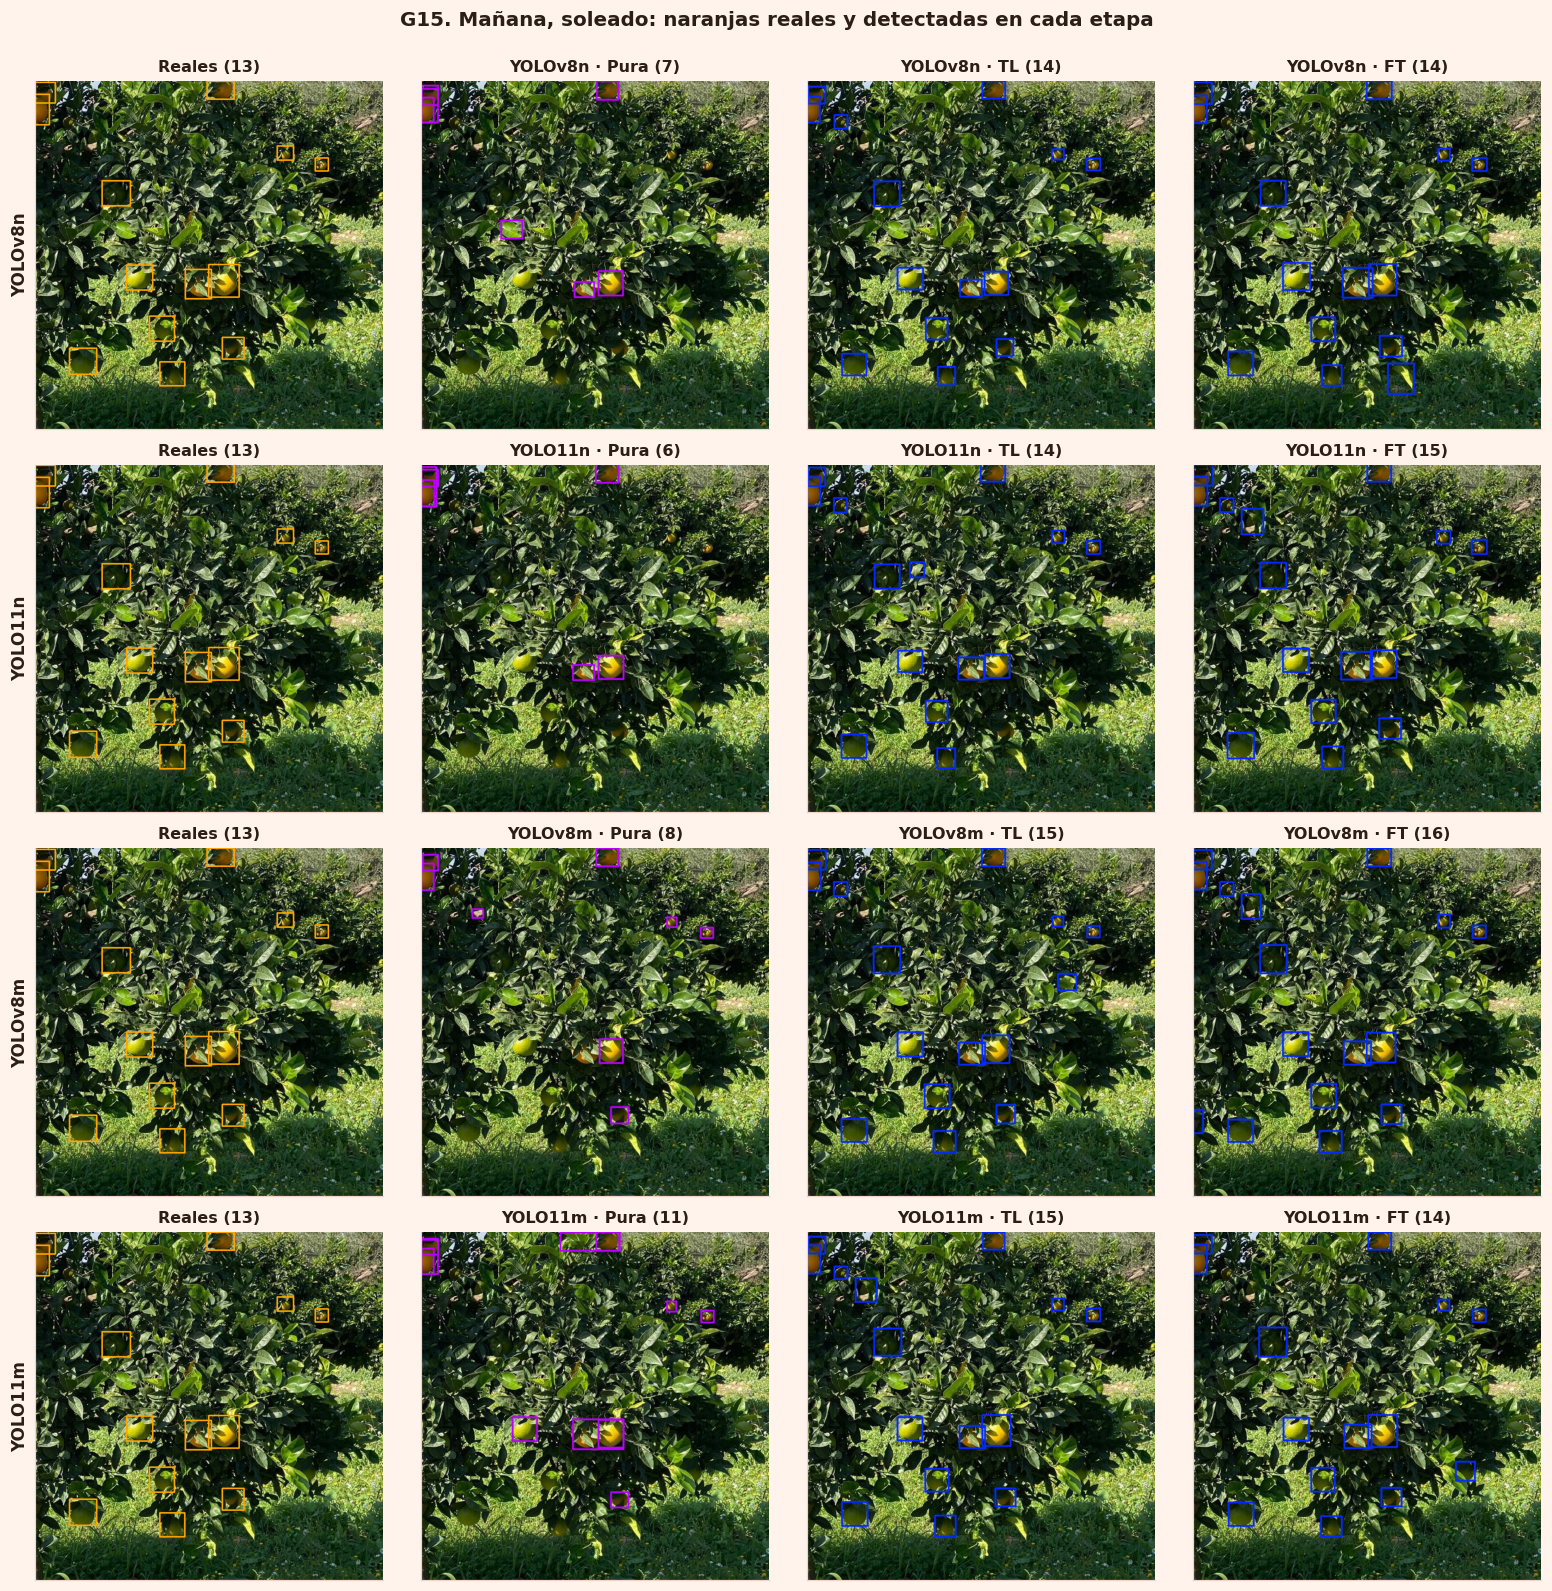

In [ ]:
# G15. Una imagen de test: reales vs las tres etapas de cada modelo
conteo = np.array([len(leer_cajas(a, 'test')) for a in test_tabla['archivo']])
archivo = test_tabla['archivo'].iloc[int(np.argsort(conteo)[int(len(conteo) * 0.75)])]   # Percentil 75 de naranjas por imagen
imagen = cv2.imread(str(ruta_imagen(archivo, 'test')))
cajas = leer_cajas(archivo, 'test', imagen.shape[1], imagen.shape[0])
reales = imagen.copy()
for x1, y1, x2, y2 in cajas.astype(int):
    cv2.rectangle(reales, (x1, y1), (x2, y2), (0, 165, 255), 2)

fig, ejes = plt.subplots(len(ORDEN), len(ETAPAS) + 1, figsize=(3.6 * (len(ETAPAS) + 1), 3.6 * len(ORDEN)))
for i, tipo in enumerate(ORDEN):
    ejes[i, 0].imshow(a_rgb(reales))
    ejes[i, 0].set_title(f'Reales ({len(cajas)})')
    ejes[i, 0].set_ylabel(tipo, fontsize=11)
    for j, etapa in enumerate(ETAPAS, start=1):
        modelo = cargar_modelo(pesos_de(tipo, etapa, semilla_de(tipo, etapa)))
        clases = [ID_NARANJA_COCO] if etapa == 'Pura (COCO)' else None
        r = modelo.predict(imagen, conf=float(fila_de(tipo, etapa)['Umbral conf. (val)']), classes=clases, imgsz=IMGSZ, verbose=False)[0]
        ejes[i, j].imshow(a_rgb(r.plot(labels=False, conf=False)))
        ejes[i, j].set_title(f'{tipo} · {ETAPA_CORTA[etapa]} ({len(r.boxes)})')
        del modelo
for ax in ejes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle(f'G15. {ENTORNOS[archivo[:2]]}: naranjas reales y detectadas en cada etapa', y=1.0, fontsize=13)
plt.tight_layout()
guardar(fig, 'G15_deteccion_por_etapa.png')
liberar_memoria()

---
## 7. Conclusiones
La celda siguiente resume los resultados **calculados** en este notebook: si se vuelve a entrenar, los números cambian solos.
Después hay preguntas guía para redactar las conclusiones del informe o la presentación.

In [ ]:
# 7.1 Resumen automático de los resultados
ft_medias = medias.xs('Fine-tuning', level='Etapa').loc[ORDEN]
col_vel = 'GPU (ms/img)' if 'GPU (ms/img)' in velocidad else 'CPU (ms/img)'
lineas = [f"Modelo final (mayor mAP50-95 en validación): {MEJOR['mAP50-95 val'].idxmax()}",
          f"Mayor mAP50-95 en test: {ft_medias['mAP50-95'].idxmax()} ({ft_medias['mAP50-95'].max():.3f})",
          f"Más rápido ({col_vel.split()[0]}): {velocidad[col_vel].idxmin()} ({velocidad[col_vel].min():.1f} ms/img, "
          f"{1000 / velocidad[col_vel].min():.0f} FPS)", '', 'Etapas (mAP50-95 en test):']
for tipo in ORDEN:
    pura, tl, ft_ = tabla_etapas.loc[tipo, ETAPAS]
    lineas.append(f'  {tipo}: Pura {pura:.3f} → TL {tl:.3f} ({tl - pura:+.3f}) → FT {ft_:.3f} ({ft_ - tl:+.3f})')
lineas += ['', 'Generación (mismo tamaño, fine-tuning):']
for tam in 'nm':
    v8, v11 = f'YOLOv8{tam}', f'YOLO11{tam}'
    lineas.append(f"  {v11} vs {v8}: mAP50-95 {ft_medias.loc[v11, 'mAP50-95'] - ft_medias.loc[v8, 'mAP50-95']:+.3f}, "
                  f"latencia {velocidad.loc[v11, col_vel]:.1f} vs {velocidad.loc[v8, col_vel]:.1f} ms, "
                  f"parámetros {velocidad.loc[v11, 'Parámetros (M)']:.1f} vs {velocidad.loc[v8, 'Parámetros (M)']:.1f} M")
lineas += ['', 'Tamaño (misma generación, fine-tuning):']
for gen in ('YOLOv8', 'YOLO11'):
    n, m = f'{gen}n', f'{gen}m'
    lineas.append(f"  {m} vs {n}: mAP50-95 {ft_medias.loc[m, 'mAP50-95'] - ft_medias.loc[n, 'mAP50-95']:+.3f}, "
                  f"{velocidad.loc[m, col_vel] / velocidad.loc[n, col_vel]:.1f}× más lento, "
                  f"{velocidad.loc[m, 'Parámetros (M)'] / velocidad.loc[n, 'Parámetros (M)']:.1f}× más parámetros")
if len(SEMILLAS) == 1:
    lineas += ['', 'Nota: con 1 semilla, diferencias de ≈ 0.01 en mAP50-95 pueden deberse al azar (perfil "completo" para confirmarlas).']
print('\n'.join(lineas))
(CARPETA_RESULTADOS / 'conclusiones.txt').write_text('\n'.join(lineas), encoding='utf-8')

Modelo final (mayor mAP50-95 en validación): YOLO11m
Mayor mAP50-95 en test: YOLO11m (0.439)
Más rápido (GPU): YOLOv8n (7.6 ms/img, 132 FPS)

Etapas (mAP50-95 en test):
  YOLOv8n: Pura 0.222 → TL 0.379 (+0.157) → FT 0.416 (+0.037)
  YOLO11n: Pura 0.227 → TL 0.386 (+0.159) → FT 0.424 (+0.038)
  YOLOv8m: Pura 0.270 → TL 0.423 (+0.152) → FT 0.434 (+0.012)
  YOLO11m: Pura 0.274 → TL 0.433 (+0.159) → FT 0.439 (+0.006)

Generación (mismo tamaño, fine-tuning):
  YOLO11n vs YOLOv8n: mAP50-95 +0.008, latencia 9.7 vs 7.6 ms, parámetros 2.6 vs 3.1 M
  YOLO11m vs YOLOv8m: mAP50-95 +0.005, latencia 27.9 vs 27.6 ms, parámetros 20.1 vs 25.9 M

Tamaño (misma generación, fine-tuning):
  YOLOv8m vs YOLOv8n: mAP50-95 +0.018, 3.6× más lento, 8.2× más parámetros
  YOLO11m vs YOLO11n: mAP50-95 +0.015, 2.9× más lento, 7.7× más parámetros


826

### 7.2 Preguntas guía
1. **Etapas:** ¿cuánto mejora cada modelo de Pura a Transfer learning y de Transfer learning a Fine-tuning (G1, G2, G10)? ¿Qué parte de la mejora total llega ya con el transfer learning?
2. **Generación:** con el mismo tamaño, ¿YOLO11 supera a YOLOv8 (G3)? ¿Es más rápido (G11)? ¿Coincide con lo que Ultralytics informa en COCO (sección 3.7)?
3. **Tamaño:** ¿cuánto se gana de *n* a *m* y cuánto cuesta en latencia y en tiempo de entrenamiento (G11, tabla 5.6)?
4. **Entrenamiento:** ¿hubo sobreajuste (G6)? ¿Cortó el *early stopping*, o el mAP seguía subiendo en la última época (G5)? En ese caso, más épocas podrían ayudar.
5. **Errores:** ¿los modelos fallan más por FN (naranjas perdidas) o por FP (falsas alarmas) (G8, G14)? ¿En qué entornos (G12)?
6. **Elección:** ¿qué modelo usarías en la demo con GPU? ¿Y en un dispositivo sin GPU (latencia de CPU en la tabla 5.9)?

---
## 8. Guardar los modelos y elegir el modelo final
Se copian los mejores pesos fine-tuned de cada modelo a la carpeta `modelos/v4/` del proyecto, con nombres claros, y se escribe `modelos.json` con:
qué modelo es el final, el umbral de confianza de cada uno y sus métricas.

El **modelo final** es el de mayor **mAP50-95 en validación**. No se elige con test: si eligiéramos "el que mejor sale en test",
el número de test dejaría de ser una medida honesta de cómo funcionará con imágenes nuevas.
Si para tu caso importa más la velocidad (por ejemplo, una cámara en tiempo real sin GPU), mira también la tabla de la sección 5.9 y la gráfica G11.

In [ ]:
# 8.1 Guardar
FINAL = MEJOR['mAP50-95 val'].idxmax()
info = {'final': FINAL, 'experimento': NOMBRE_EXPERIMENTO, 'perfil': PERFIL, 'imgsz': IMGSZ, 'modelos': {}}
for tipo, pesos in PESOS_MEJORES.items():
    archivo = f"orange_{tipo.lower().replace('-', '')}.pt"
    shutil.copy(pesos, CARPETA_MODELOS / archivo)
    info['modelos'][tipo] = {'archivo': archivo,
                             'umbral_conf': round(float(MEJOR.loc[tipo, 'Umbral conf. (val)']), 3),
                             'mAP50-95 val': round(float(MEJOR.loc[tipo, 'mAP50-95 val']), 4),
                             'mAP50-95 test': round(float(MEJOR.loc[tipo, 'mAP50-95']), 4),
                             'mAP50-95 test por etapa': {e: round(float(tabla_etapas.loc[tipo, e]), 4) for e in ETAPAS}}
(CARPETA_MODELOS / 'modelos.json').write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(info, indent=2, ensure_ascii=False))
print(f'\nModelo final: {FINAL}. Archivos en {CARPETA_MODELOS}')

{
  "final": "YOLO11m",
  "experimento": "v4_N1500",
  "perfil": "completo",
  "imgsz": 640,
  "modelos": {
    "YOLOv8n": {
      "archivo": "orange_yolov8n.pt",
      "umbral_conf": 0.323,
      "mAP50-95 val": 0.4007,
      "mAP50-95 test": 0.4163,
      "mAP50-95 test por etapa": {
        "Pura (COCO)": 0.222,
        "Transfer learning": 0.3793,
        "Fine-tuning": 0.4163
      }
    },
    "YOLO11n": {
      "archivo": "orange_yolo11n.pt",
      "umbral_conf": 0.352,
      "mAP50-95 val": 0.4087,
      "mAP50-95 test": 0.4243,
      "mAP50-95 test por etapa": {
        "Pura (COCO)": 0.2267,
        "Transfer learning": 0.3858,
        "Fine-tuning": 0.4242
      }
    },
    "YOLOv8m": {
      "archivo": "orange_yolov8m.pt",
      "umbral_conf": 0.356,
      "mAP50-95 val": 0.418,
      "mAP50-95 test": 0.4365,
      "mAP50-95 test por etapa": {
        "Pura (COCO)": 0.2704,
        "Transfer learning": 0.4228,
        "Fine-tuning": 0.4344
      }
    },
    "YOLO11m": {
 

---
## 9. Usar el modelo entrenado (sin volver a entrenar)
Los modelos quedan guardados en `modelos/v4/` dentro de la carpeta del proyecto. Para usarlos otro día **no hace falta entrenar de nuevo**:
1. Ejecuta las celdas de la **sección 1** (instalación, configuración, carpetas y funciones).
2. Ejecuta las celdas de esta sección.

También puedes usar los modelos fuera de este notebook con dos líneas:
```python
from ultralytics import YOLO
modelo = YOLO('modelos/v4/orange_yolo11m.pt')
modelo.predict('foto.jpg', conf=0.3, show=True)
```

In [ ]:
# 9.1 Cargar los modelos guardados
info_modelos = json.loads((CARPETA_MODELOS / 'modelos.json').read_text(encoding='utf-8'))
MODELO_FINAL = info_modelos['final']
modelos_listos = {tipo: cargar_modelo(CARPETA_MODELOS / d['archivo']) for tipo, d in info_modelos['modelos'].items()}
UMBRALES = {tipo: d['umbral_conf'] for tipo, d in info_modelos['modelos'].items()}
print('Modelos cargados:', list(modelos_listos), '| final:', MODELO_FINAL)


def mostrar_detecciones(imagen, comparar=True):
    """Dibuja las naranjas detectadas. imagen = ruta o imagen de OpenCV. comparar=True usa los cuatro modelos."""
    if not isinstance(imagen, np.ndarray):
        ruta = imagen
        imagen = cv2.imread(str(ruta))
        if imagen is None:
            print(f'No se pudo leer {ruta}. Usa una imagen .jpg o .png.')
            return
    tipos = list(modelos_listos) if comparar else [MODELO_FINAL]
    fig, ejes = plt.subplots(1, len(tipos), figsize=(5 * len(tipos), 5), squeeze=False)
    for ax, tipo in zip(ejes[0], tipos):
        r = modelos_listos[tipo].predict(imagen, conf=UMBRALES[tipo], imgsz=IMGSZ, verbose=False)[0]
        ax.imshow(a_rgb(r.plot(labels=False)))
        ax.set_title(f'{tipo}: {len(r.boxes)} naranjas (conf ≥ {UMBRALES[tipo]:.2f})')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

Modelos cargados: ['YOLOv8n', 'YOLO11n', 'YOLOv8m', 'YOLO11m'] | final: YOLO11m


### 9.2 Probar con una imagen subida (sin cámara)
- **En Colab**: al ejecutar la celda aparece un botón *Elegir archivos*; puedes subir una o varias fotos.
- **En tu computadora**: escribe la ruta de tus fotos en `IMAGENES_LOCALES`.

Pon `COMPARAR_TODOS = False` para ver solo el modelo final.

In [ ]:
# 9.2 Subir imágenes y detectar naranjas
COMPARAR_TODOS = True
IMAGENES_LOCALES = ['naranjas.jpg']   # Solo se usa fuera de Colab

if EN_COLAB:
    from google.colab import files
    rutas = list(files.upload())     # Guarda las fotos subidas en /content
else:
    rutas = [r for r in IMAGENES_LOCALES if Path(r).exists()]
    if not rutas:
        print('No se encontró ninguna imagen en IMAGENES_LOCALES; se usa una de test como ejemplo.')
        rutas = [ruta_imagen(test_tabla['archivo'].iloc[0], 'test')] if 'test_tabla' in globals() else []

for ruta in rutas:
    mostrar_detecciones(ruta, comparar=COMPARAR_TODOS)

### 9.3 Webcam en tiempo real (solo en tu computadora)
Colab se ejecuta en un servidor remoto y no puede abrir una ventana de video. En tu computadora (Jupyter o VS Code), pon `USAR_WEBCAM = True`.
Se abre una ventana con las naranjas detectadas, el conteo y los FPS. Pulsa **q** o **ESC** para salir.

In [ ]:
# 9.3 Detección en vivo con la webcam
USAR_WEBCAM = False
CAMARA = 0   # Si tienes varias cámaras, prueba 1 o 2


def detectar_en_webcam(tipo=None, camara=0):
    tipo = tipo or MODELO_FINAL
    modelo, umbral = modelos_listos[tipo], UMBRALES[tipo]
    cap = cv2.VideoCapture(camara)
    if not cap.isOpened():
        print(f'No se pudo abrir la cámara {camara}.')
        return
    anterior = time.time()
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            r = modelo.predict(frame, conf=umbral, imgsz=IMGSZ, verbose=False)[0]
            frame = r.plot(labels=False)
            ahora = time.time()
            fps, anterior = 1 / max(ahora - anterior, 1e-6), ahora
            cv2.rectangle(frame, (0, 0), (330, 70), (0, 0, 0), -1)
            cv2.putText(frame, f'{tipo}  FPS: {fps:.1f}', (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
            cv2.putText(frame, f'Naranjas: {len(r.boxes)}', (10, 58), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 165, 255), 2)
            cv2.imshow('Orange Vision', frame)
            if cv2.waitKey(1) & 0xFF in (ord('q'), 27):
                break
    finally:
        cap.release()
        cv2.destroyAllWindows()


if USAR_WEBCAM and not EN_COLAB:
    detectar_en_webcam(camara=CAMARA)
elif USAR_WEBCAM:
    print('En Colab usa la celda 9.4 para tomar una foto con la cámara del navegador.')

### 9.4 Foto con la cámara del navegador (Colab)
En Colab sí se puede tomar **una foto** con la cámara de tu navegador. Pon `TOMAR_FOTO = True`, ejecuta la celda y pulsa el botón que aparece.

In [ ]:
# 9.4 Tomar una foto en Colab y detectar naranjas
TOMAR_FOTO = True

if TOMAR_FOTO and EN_COLAB:
    import base64
    from IPython.display import Javascript, display
    from google.colab.output import eval_js

    display(Javascript("""
    async function tomarFoto(calidad) {
      const div = document.createElement('div');
      const boton = document.createElement('button');
      boton.textContent = 'Tomar foto';
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(boton);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      await new Promise((resolve) => boton.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', calidad);
    }
    """))
    datos = eval_js('tomarFoto(0.9)')
    Path('foto_webcam.jpg').write_bytes(base64.b64decode(datos.split(',')[1]))
    mostrar_detecciones('foto_webcam.jpg', comparar=True)
elif TOMAR_FOTO:
    print('Esta celda es para Colab. En tu computadora usa la celda 9.3.')

<IPython.core.display.Javascript object>

MessageError: NotFoundError: Requested device not found

---
## 10. Glosario rápido

| Término | Significado breve |
|---|---|
| Neurona / peso | Unidad que multiplica entradas por pesos, suma y aplica una activación. Los pesos son lo que se aprende |
| CNN | Red que usa filtros que se deslizan por la imagen (convolución) para extraer características |
| Feature map | Resultado de aplicar un filtro: un "mapa" de dónde aparece cierta característica |
| Backbone / neck / head | Extraer características / combinar escalas / predecir cajas y clases |
| Transformer / atención | Arquitectura donde cada parte de la entrada pondera a todas las demás (contexto global) |
| YOLO | Detector de una etapa: predice todas las cajas en una sola pasada |
| YOLOv8 / YOLO11 | Versiones de YOLO de Ultralytics (2023 / 2024); *n* = nano, *m* = medium |
| C2f / C3k2 | Bloque principal de YOLOv8 / su versión más ligera en YOLO11 |
| C2PSA | Bloque de atención de YOLO11 al final del backbone |
| *Anchor-free* | Predecir el centro y tamaño del objeto sin cajas de referencia predefinidas |
| Preentrenado / COCO | Modelo ya entrenado en un dataset grande (COCO: 118k imágenes, 80 clases) |
| Etapa Pura | Usar el modelo de COCO tal cual, sin entrenarlo con nuestras fotos |
| Transfer learning | Reutilizar lo aprendido en una tarea para otra. En sentido estricto (*feature extraction*): backbone congelado, solo se entrenan neck y head |
| Fine-tuning | Seguir entrenando **toda** la red preentrenada con datos propios y un *learning rate* pequeño |
| Olvido catastrófico | Perder lo aprendido en COCO por actualizar los pesos con pasos demasiado grandes |
| *Domain shift* | Diferencia entre los datos con los que se entrenó (COCO) y los datos de uso (naranjas de campo) |
| Congelar capas | Impedir que ciertos pesos cambien durante el entrenamiento |
| Función de pérdida | Número que mide cuánto se equivoca el modelo; el entrenamiento lo minimiza |
| box / cls / dfl loss | Pérdida de la caja (CIoU) / de la clase (entropía cruzada binaria) / de la precisión fina de los bordes |
| Gradiente / retropropagación | Dirección en que cambiar cada peso / algoritmo que la calcula |
| Learning rate | Tamaño del paso al actualizar los pesos |
| Warmup | Empezar con un learning rate pequeño e ir subiéndolo |
| Optimizador (AdamW) | Regla para actualizar los pesos a partir del gradiente |
| Batch / iteración / época | Imágenes por actualización / una actualización / una pasada por todo train |
| Sobreajuste | Memorizar train en lugar de generalizar |
| Early stopping / paciencia | Parar cuando validación deja de mejorar / cuántas épocas esperar |
| Aumento de datos | Modificaciones aleatorias de las imágenes de train |
| Semilla | Número que fija el azar para poder repetir un experimento |
| AMP | Usar números de 16 bits para entrenar más rápido |
| Train / val / test | Aprender / decidir / medir el resultado final |
| Fuga de datos | Que información del test se cuele en el entrenamiento |
| IoU | Solapamiento entre dos cajas (intersección / unión) |
| NMS | Eliminar cajas duplicadas del mismo objeto |
| TP / FP / FN | Acierto / falsa alarma / objeto no detectado |
| Matriz de confusión (detección) | Tabla con TP, FN y FP contando cajas; no tiene verdaderos negativos |
| Precisión / recall / F1 | Calidad de las detecciones / cobertura de objetos / equilibrio |
| mAP50 / mAP50-95 | Área bajo la curva precisión-recall con IoU 0.5 / promediada entre IoU 0.5 y 0.95 |
| Umbral de confianza | Confianza mínima para aceptar una detección |
| Curva PR / curva F1 | Precisión según el recall / F1 según el umbral de confianza |
| Frontera de Pareto | Modelos que ningún otro supera a la vez en velocidad y en precisión |
| Parámetros / GFLOPs | Tamaño del modelo / coste de cálculo por imagen |
| Latencia / FPS | Tiempo por imagen / imágenes por segundo |